In [64]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu, kruskal

from statsmodels.stats.multitest import multipletests

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TOP_N_GENES = 30

OUTPUT_DIR = "/kaggle/working/Gene_Expression_Analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

# ALL_AML
ALL_AML_TRAIN_PATH = "/kaggle/input/datasets/crawford/gene-expression/data_set_ALL_AML_train.csv"

ALL_AML_LABEL_PATH = "/kaggle/input/datasets/crawford/gene-expression/actual.csv"

ALL_AML_TEST_PATH = "/kaggle/input/datasets/crawford/gene-expression/data_set_ALL_AML_independent.csv"

# Armstrong
ARM2_PATH = "/kaggle/input/datasets/lknurkoparr/armstrong-dataset/Arm2.csv"

print("Kütüphaneler ve dosya yolları hazır.")

Kütüphaneler ve dosya yolları hazır.


In [65]:
def load_all_aml(expression_path, label_path):

    df = pd.read_csv(expression_path)
    labels = pd.read_csv(label_path)

    sample_columns = [
        c for c in df.columns
        if str(c).strip().isdigit()
    ]

    gene_col = (
        "Gene Accession Number"
        if "Gene Accession Number" in df.columns
        else "Gene Accession"
    )

    if gene_col not in df.columns:
        raise ValueError("Gen kimliği sütunu bulunamadı.")

    genes = df[gene_col].astype(str)

    X = df[sample_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    X.index = genes
    X = X.T

    X.index = X.index.astype(int)

    # Aynı gen kimliğine sahip probları ortalama ile birleştir
    X = X.T.groupby(level=0).mean().T

    labels["patient"] = pd.to_numeric(
        labels["patient"],
        errors="coerce"
    )

    labels = labels.dropna(subset=["patient"])

    labels["patient"] = labels["patient"].astype(int)

    labels = labels.drop_duplicates("patient")

    labels = labels.set_index("patient")

    common_samples = X.index.intersection(labels.index)

    X = X.loc[common_samples]
    y = labels.loc[common_samples, "cancer"]

    print("Örnek sayısı:", X.shape[0])
    print("Gen sayısı:", X.shape[1])

    print("\nSınıf dağılımı:")
    print(y.value_counts())

    return X, y, df


# Eğitim verisi
X_all, y_all, all_raw = load_all_aml(
    ALL_AML_TRAIN_PATH,
    ALL_AML_LABEL_PATH
)

# Bağımsız test verisi
X_independent, y_independent, independent_raw = load_all_aml(
    ALL_AML_TEST_PATH,
    ALL_AML_LABEL_PATH
)

Örnek sayısı: 38
Gen sayısı: 7129

Sınıf dağılımı:
cancer
ALL    27
AML    11
Name: count, dtype: int64
Örnek sayısı: 34
Gen sayısı: 7129

Sınıf dağılımı:
cancer
ALL    20
AML    14
Name: count, dtype: int64


In [66]:
def load_arm2(path):

    df = pd.read_csv(path)

    print("Armstrong orijinal boyutu:", df.shape)

    # Grup etiketleri
    if "group" not in df.columns:
        raise ValueError("group sütunu bulunamadı.")

    y = df["group"].copy()

    # Kimlik ve etiket sütunlarını çıkar
    X = df.drop(
        columns=["group", "Unnamed: 0"],
        errors="ignore"
    )

    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Örnek isimleri
    X.index = [
        f"ARM2_{i+1}"
        for i in range(len(X))
    ]

    y.index = X.index

    print("Armstrong örnek sayısı:", X.shape[0])
    print("Armstrong gen sayısı:", X.shape[1])

    print("\nGrup dağılımı:")
    print(y.value_counts())

    return X, y, df


X_arm2, y_arm2, arm2_raw = load_arm2(ARM2_PATH)

Armstrong orijinal boyutu: (72, 2196)
Armstrong örnek sayısı: 72
Armstrong gen sayısı: 2194

Grup dağılımı:
group
3    28
1    24
2    20
Name: count, dtype: int64


,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ALL_AML_TRAIN,38,7129,0,0,0,0,77175,738,0,10930,4937


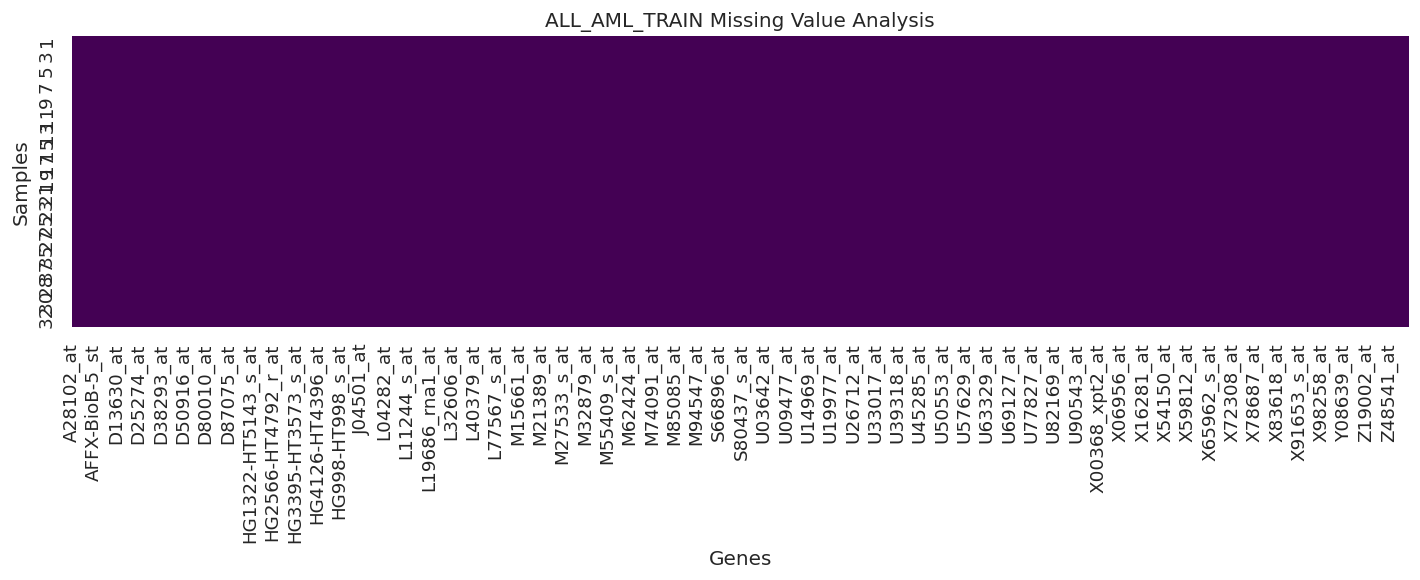

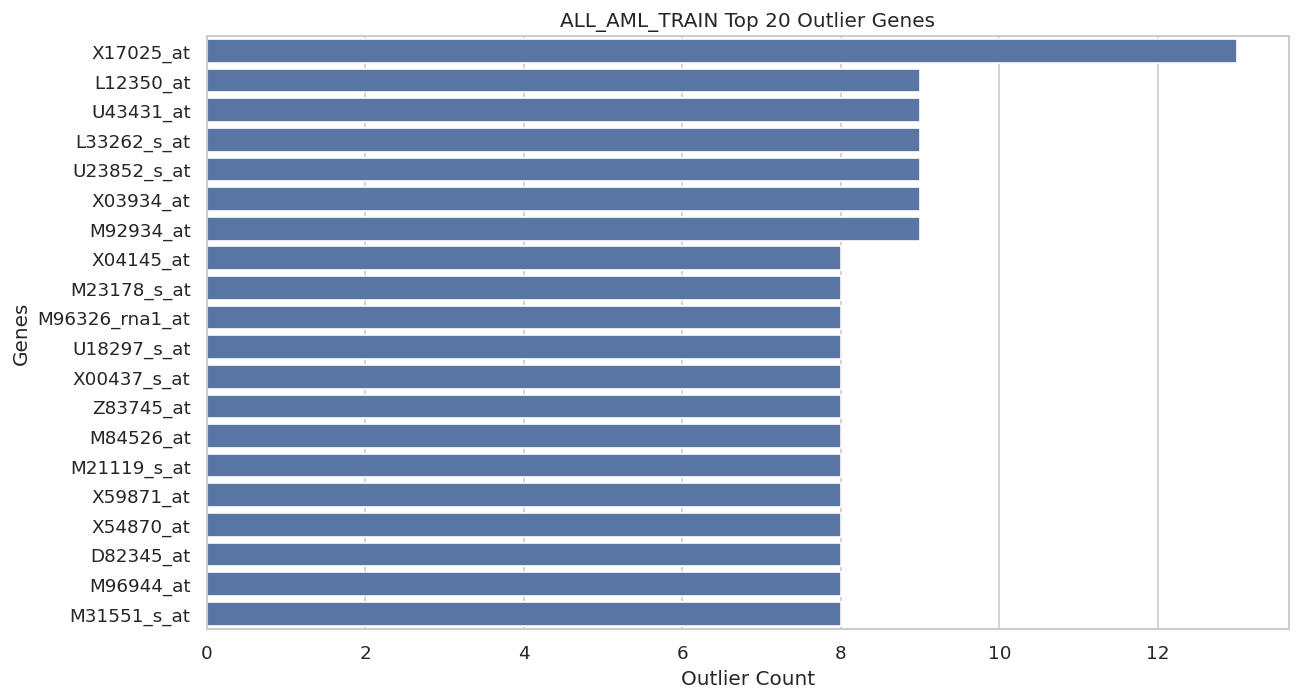

,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ALL_AML_INDEPENDENT,34,7129,0,0,0,0,69999,877,0,10938,5160


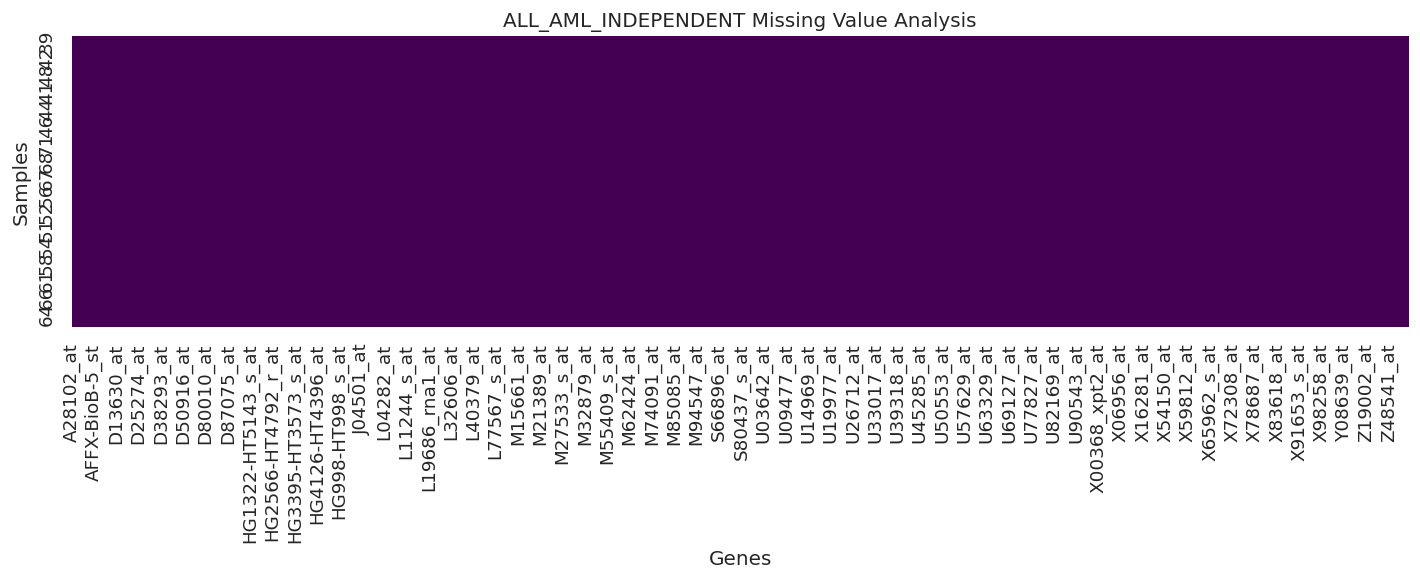

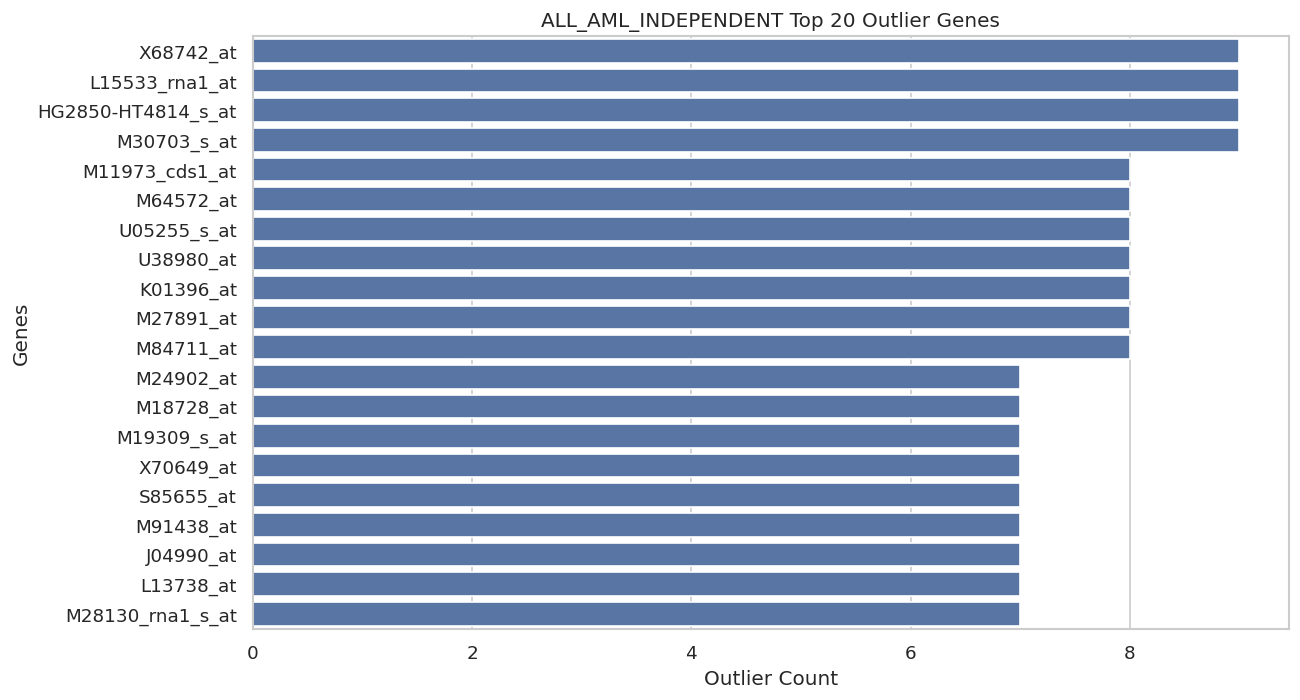

,Dataset,Samples,Genes,Missing,Positive_INF,Negative_INF,Total_INF,Negative,Zero,Duplicate_Genes,Total_Outliers,Genes_With_Outliers
0,ARMSTRONG,72,2194,0,0,0,0,79162,0,0,2243,250


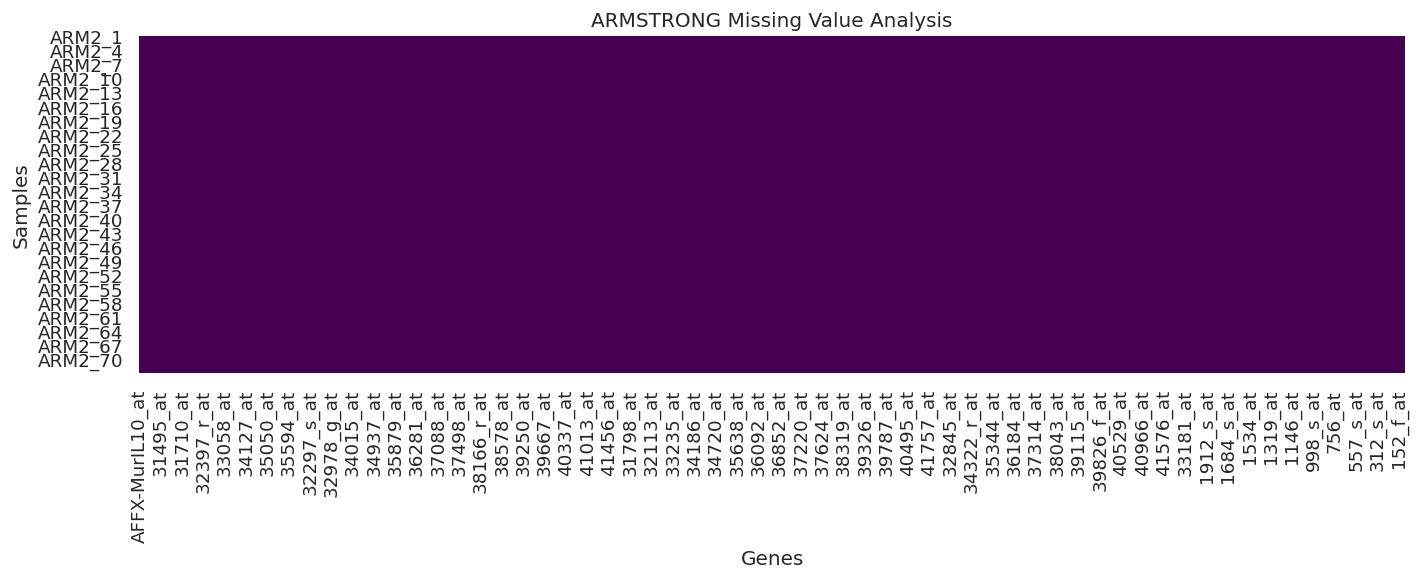

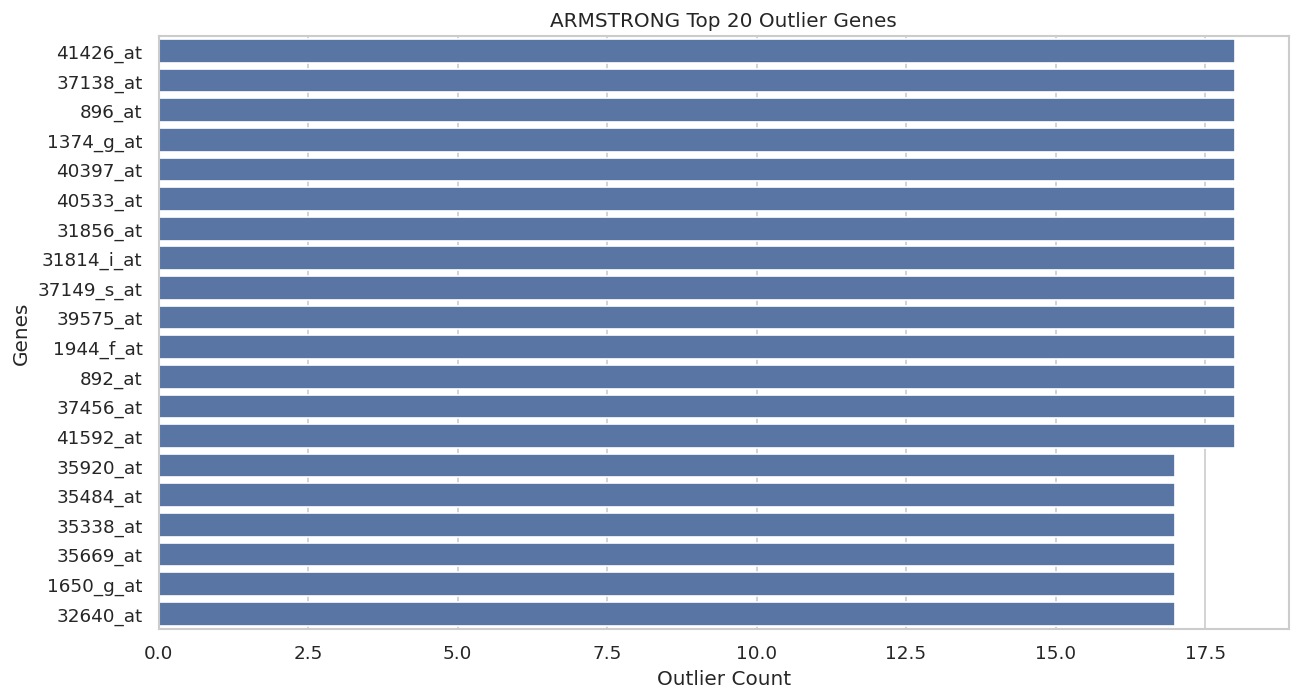


ALL_AML_TRAIN - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 77175
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 738

ALL_AML_INDEPENDENT - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 69999
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 877

ARMSTRONG - negatif değer ön işlemi
1 ile değiştirilen negatif değer sayısı: 79162
İşlem sonrası negatif değer sayısı: 0
İşlem sonrası sıfır değer sayısı: 0

ALL_AML_TRAIN - LOG DÖNÜŞÜMÜ ÖNCESİ
Veri boyutu: (38, 7129)
Minimum değer: 0.0
Maksimum değer: 61228.0
Ortalama: 708.4419051908069
Standart sapma: 352.69281666004076
Ortalama çarpıklık: 1.6707876637571544

ALL_AML_TRAIN - LOG DÖNÜŞÜMÜ SONRASI
Veri boyutu: (38, 7129)
Minimum değer: -inf
Maksimum değer: 15.90190393807474
Ortalama: -inf
Standart sapma: 1.6500371468550443
Ortalama çarpıklık: -0.2593480144426071


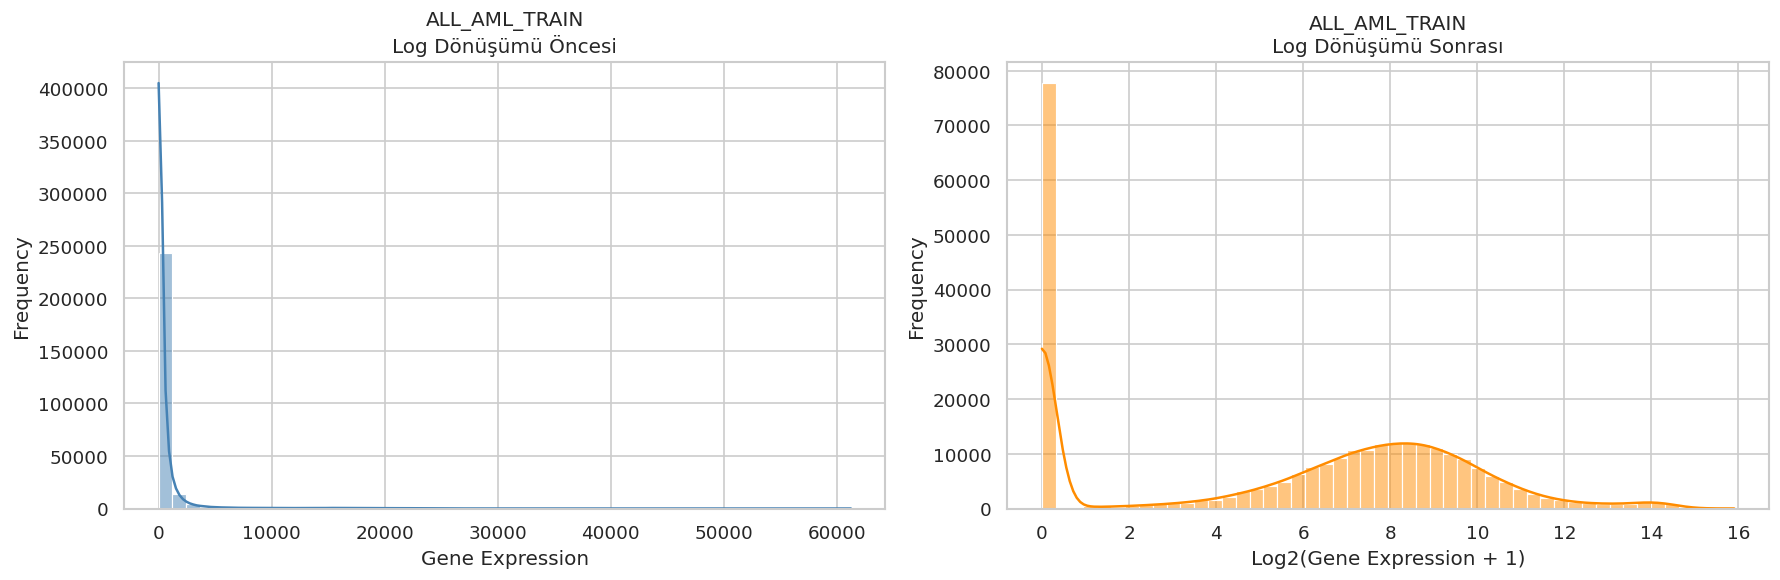


ALL_AML_TRAIN - İstatistiksel Karşılaştırma


,Metric,Before_Log,After_Log
0,Minimum,0.000000,-inf
1,Maximum,61228.000000,15.901904
2,Mean,708.441905,-inf
3,Standard Deviation,352.692817,1.650037
4,Mean Skewness,1.670788,-0.259348



ALL_AML_INDEPENDENT - LOG DÖNÜŞÜMÜ ÖNCESİ
Veri boyutu: (34, 7129)
Minimum değer: 0.0
Maksimum değer: 71369.0
Ortalama: 662.7522711707771
Standart sapma: 349.39010661660654
Ortalama çarpıklık: 1.6924957935616416

ALL_AML_INDEPENDENT - LOG DÖNÜŞÜMÜ SONRASI
Veri boyutu: (34, 7129)
Minimum değer: -inf
Maksimum değer: 16.12300993758573
Ortalama: -inf
Standart sapma: 1.793740375612332
Ortalama çarpıklık: -0.263676288137453


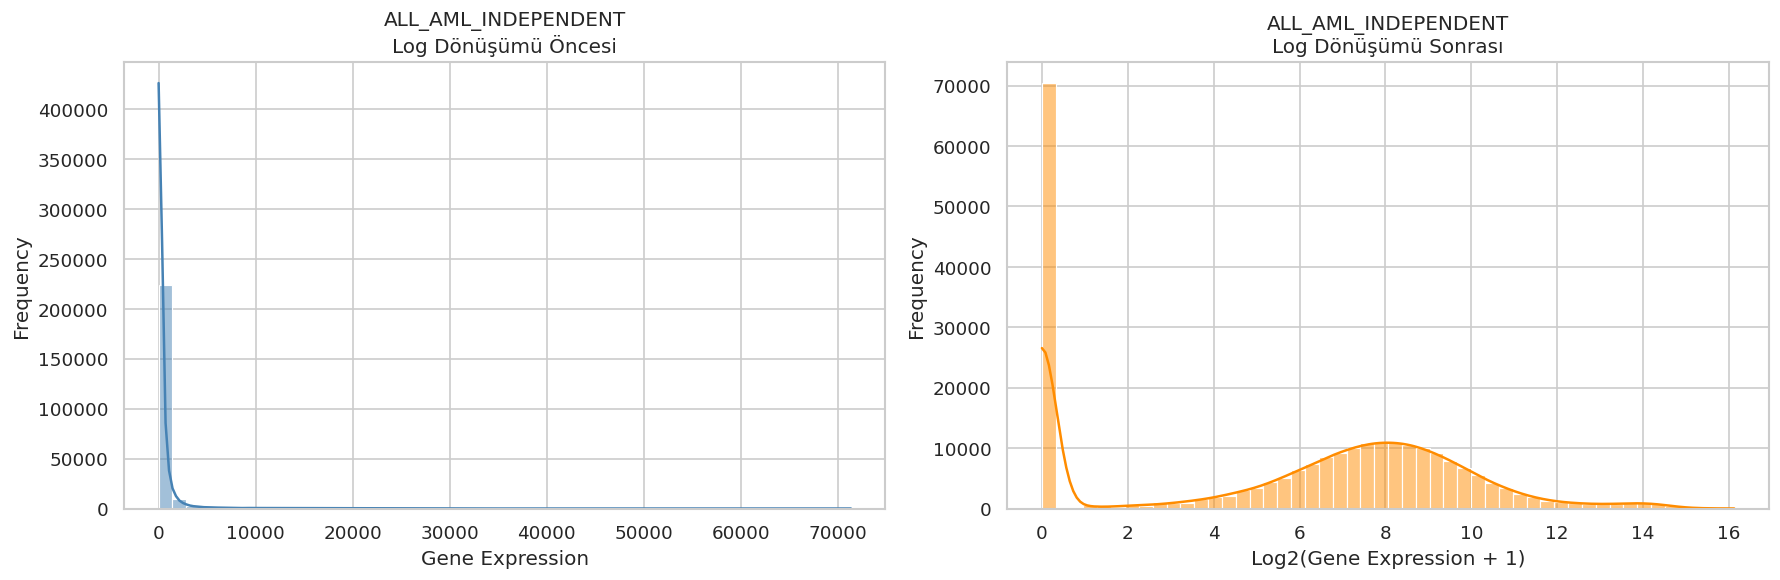


ALL_AML_INDEPENDENT - İstatistiksel Karşılaştırma


,Metric,Before_Log,After_Log
0,Minimum,0.000000,-inf
1,Maximum,71369.000000,16.123010
2,Mean,662.752271,-inf
3,Standard Deviation,349.390107,1.793740
4,Mean Skewness,1.692496,-0.263676



ARMSTRONG - LOG DÖNÜŞÜMÜ ÖNCESİ
Veri boyutu: (72, 2194)
Minimum değer: 0.0001006605646242
Maksimum değer: 5.78888196765421
Ortalama: 0.9387987231367058
Standart sapma: 0.35268786010455266
Ortalama çarpıklık: 0.05375495446956488

ARMSTRONG - LOG DÖNÜŞÜMÜ SONRASI
Veri boyutu: (72, 2194)
Minimum değer: -13.27821378422917
Maksimum değer: 2.5332847410518613
Ortalama: -0.28156220924801634
Standart sapma: 0.8777086627052793
Ortalama çarpıklık: -2.4208588607657724


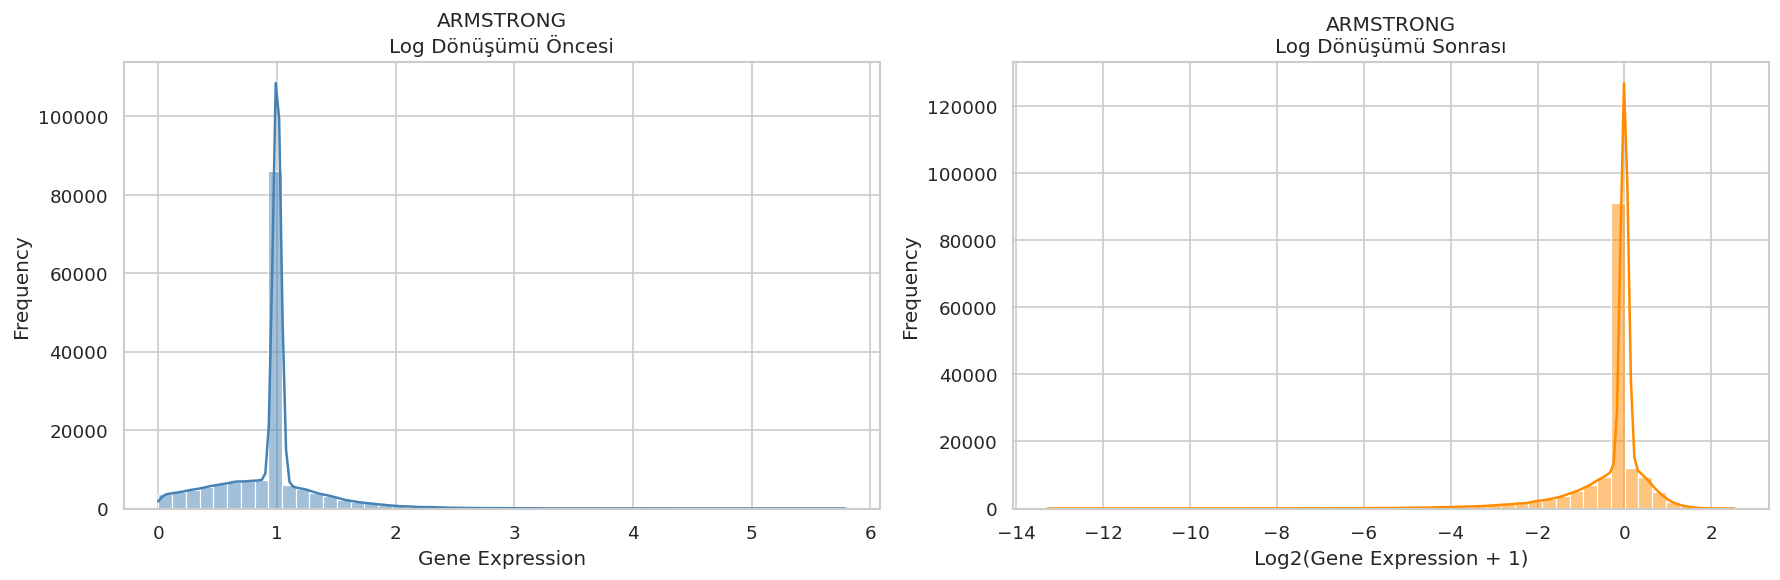


ARMSTRONG - İstatistiksel Karşılaştırma


,Metric,Before_Log,After_Log
0,Minimum,0.000101,-13.278214
1,Maximum,5.788882,2.533285
2,Mean,0.938799,-0.281562
3,Standard Deviation,0.352688,0.877709
4,Mean Skewness,0.053755,-2.420859


In [67]:
def data_quality_analysis(X, dataset_name):

    X = X.apply(pd.to_numeric, errors="coerce")

    positive_inf = np.isposinf(X).sum().sum()
    negative_inf = np.isneginf(X).sum().sum()

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # IQR hesaplaması
    Q1 = X.quantile(0.25)
    Q3 = X.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        X.lt(lower, axis=1) |
        X.gt(upper, axis=1)
    )

    outlier_counts = outlier_mask.sum()

    report = {
        "Dataset": dataset_name,
        "Samples": X.shape[0],
        "Genes": X.shape[1],
        "Missing": X.isna().sum().sum(),
        "Positive_INF": positive_inf,
        "Negative_INF": negative_inf,
        "Total_INF": positive_inf + negative_inf,
        "Negative": (X < 0).sum().sum(),
        "Zero": (X == 0).sum().sum(),
        "Duplicate_Genes": X.columns.duplicated().sum(),
        "Total_Outliers": outlier_mask.sum().sum(),
        "Genes_With_Outliers": (outlier_counts > 0).sum()
    }

    report_df = pd.DataFrame([report])

    display(report_df)

    report_df.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_quality.csv",
        index=False
    )

    outlier_counts.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_outlier_counts.csv"
    )

    # Eksik değer grafiği
    plt.figure(figsize=(12, 5))

    sns.heatmap(
        X.isna(),
        cmap="viridis",
        cbar=False
    )

    plt.title(f"{dataset_name} Missing Value Analysis")
    plt.xlabel("Genes")
    plt.ylabel("Samples")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_missing.png",
        dpi=300
    )

    plt.show()

    # En fazla aykırı değer içeren 20 gen
    top_outliers = outlier_counts.sort_values(
        ascending=False
    ).head(20)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=top_outliers.values,
        y=top_outliers.index.astype(str)
    )

    plt.title(f"{dataset_name} Top 20 Outlier Genes")
    plt.xlabel("Outlier Count")
    plt.ylabel("Genes")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_outliers.png",
        dpi=300
    )

    plt.show()

    return X


X_all = data_quality_analysis(X_all, "ALL_AML_TRAIN")

X_independent = data_quality_analysis(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

X_arm2 = data_quality_analysis(X_arm2, "ARMSTRONG")
# ============================================================
# NEGATİF İFADE DEĞERLERİNİ 1 İLE DEĞİŞTİRME
# Bu adım veri kalitesi raporları oluşturulduktan sonra uygulanır.
# Böylece özgün negatif değer sayıları raporlarda korunur.
# Bundan sonraki analizler güncellenmiş X matrislerini kullanır.
# ============================================================

def replace_negative_values_with_one(X, dataset_name):

    X = X.copy()

    negative_mask = X < 0
    negative_count = int(negative_mask.sum().sum())

    # Yalnızca negatif değerleri 1 ile değiştirir.
    # Sıfır değerler bu adımda değiştirilmez.
    X = X.mask(negative_mask, 1)

    print(f"\n{dataset_name} - negatif değer ön işlemi")
    print("1 ile değiştirilen negatif değer sayısı:", negative_count)
    print("İşlem sonrası negatif değer sayısı:", int((X < 0).sum().sum()))
    print("İşlem sonrası sıfır değer sayısı:", int((X == 0).sum().sum()))

    summary = pd.DataFrame([{
        "Dataset": dataset_name,
        "Negative_Values_Replaced_With_1": negative_count,
        "Negative_Values_After": int((X < 0).sum().sum()),
        "Zero_Values_After": int((X == 0).sum().sum())
    }])

    summary.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_negative_value_replacement.csv",
        index=False
    )

    return X



X_all = replace_negative_values_with_one(
    X_all,
    "ALL_AML_TRAIN"
)

X_independent = replace_negative_values_with_one(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

X_arm2 = replace_negative_values_with_one(
    X_arm2,
    "ARMSTRONG"
)
# ============================================================
# LOG DÖNÜŞÜMÜ ÖNCESİ VE SONRASI ANALİZ
# Negatif değerler daha önce 1'e dönüştürülmüştür.
# ============================================================

def log_transformation_analysis(X, dataset_name):

    # Orijinal verinin korunması
    X_before = X.copy()

    # ========================================================
    # 1. LOG DÖNÜŞÜMÜ ÖNCESİ
    # ========================================================

    print(f"\n{'='*60}")
    print(f"{dataset_name} - LOG DÖNÜŞÜMÜ ÖNCESİ")
    print(f"{'='*60}")

    print("Veri boyutu:", X_before.shape)

    print("Minimum değer:", X_before.min().min())
    print("Maksimum değer:", X_before.max().max())

    print("Ortalama:", X_before.mean().mean())
    print("Standart sapma:", X_before.std().mean())

    print(
        "Ortalama çarpıklık:",
        X_before.skew().mean()
    )

    # ========================================================
    # 2. LOG DÖNÜŞÜMÜ
    # ========================================================

    # Negatif değerler önceden 1'e dönüştürüldüğü için
    # log2(x + 1) dönüşümü uygulanabilir.

    if (X_before < 0).any().any():
        raise ValueError(
            f"{dataset_name}: Negatif değerler hâlâ mevcut."
        )

    X_after = np.log2(X_before)

    # ========================================================
    # 3. LOG DÖNÜŞÜMÜ SONRASI
    # ========================================================

    print(f"\n{'='*60}")
    print(f"{dataset_name} - LOG DÖNÜŞÜMÜ SONRASI")
    print(f"{'='*60}")

    print("Veri boyutu:", X_after.shape)

    print("Minimum değer:", X_after.min().min())
    print("Maksimum değer:", X_after.max().max())

    print("Ortalama:", X_after.mean().mean())
    print("Standart sapma:", X_after.std().mean())

    print(
        "Ortalama çarpıklık:",
        X_after.skew().mean()
    )

    # ========================================================
    # 4. LOG ÖNCESİ VE SONRASI HİSTOGRAMLARI
    # ========================================================

    before_values = X_before.to_numpy().flatten()
    after_values = X_after.to_numpy().flatten()

    # NaN değerleri kaldır
    before_values = before_values[
        np.isfinite(before_values)
    ]

    after_values = after_values[
        np.isfinite(after_values)
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 5)
    )

    # Log öncesi
    sns.histplot(
        before_values,
        bins=50,
        kde=True,
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(
        f"{dataset_name}\nLog Dönüşümü Öncesi"
    )

    axes[0].set_xlabel("Gene Expression")
    axes[0].set_ylabel("Frequency")

    # Log sonrası
    sns.histplot(
        after_values,
        bins=50,
        kde=True,
        ax=axes[1],
        color="darkorange"
    )

    axes[1].set_title(
        f"{dataset_name}\nLog Dönüşümü Sonrası"
    )

    axes[1].set_xlabel("Log2(Gene Expression + 1)")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_log_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # ========================================================
    # 5. İSTATİSTİKSEL KARŞILAŞTIRMA
    # ========================================================

    comparison = pd.DataFrame({

        "Metric": [
            "Minimum",
            "Maximum",
            "Mean",
            "Standard Deviation",
            "Mean Skewness"
        ],

        "Before_Log": [
            X_before.min().min(),
            X_before.max().max(),
            X_before.mean().mean(),
            X_before.std().mean(),
            X_before.skew().mean()
        ],

        "After_Log": [
            X_after.min().min(),
            X_after.max().max(),
            X_after.mean().mean(),
            X_after.std().mean(),
            X_after.skew().mean()
        ]

    })

    print(f"\n{dataset_name} - İstatistiksel Karşılaştırma")

    display(comparison)

    comparison.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_log_statistics.csv",
        index=False
    )

    return X_after


# ============================================================
# ALL_AML TRAIN DATASET
# ============================================================

X_all = log_transformation_analysis(
    X_all,
    "ALL_AML_TRAIN"
)


# ============================================================
# ALL_AML INDEPENDENT DATASET
# ============================================================

X_independent = log_transformation_analysis(
    X_independent,
    "ALL_AML_INDEPENDENT"
)


# ============================================================
# ARMSTRONG DATASET
# ============================================================

X_arm2 = log_transformation_analysis(
    X_arm2,
    "ARMSTRONG"
)


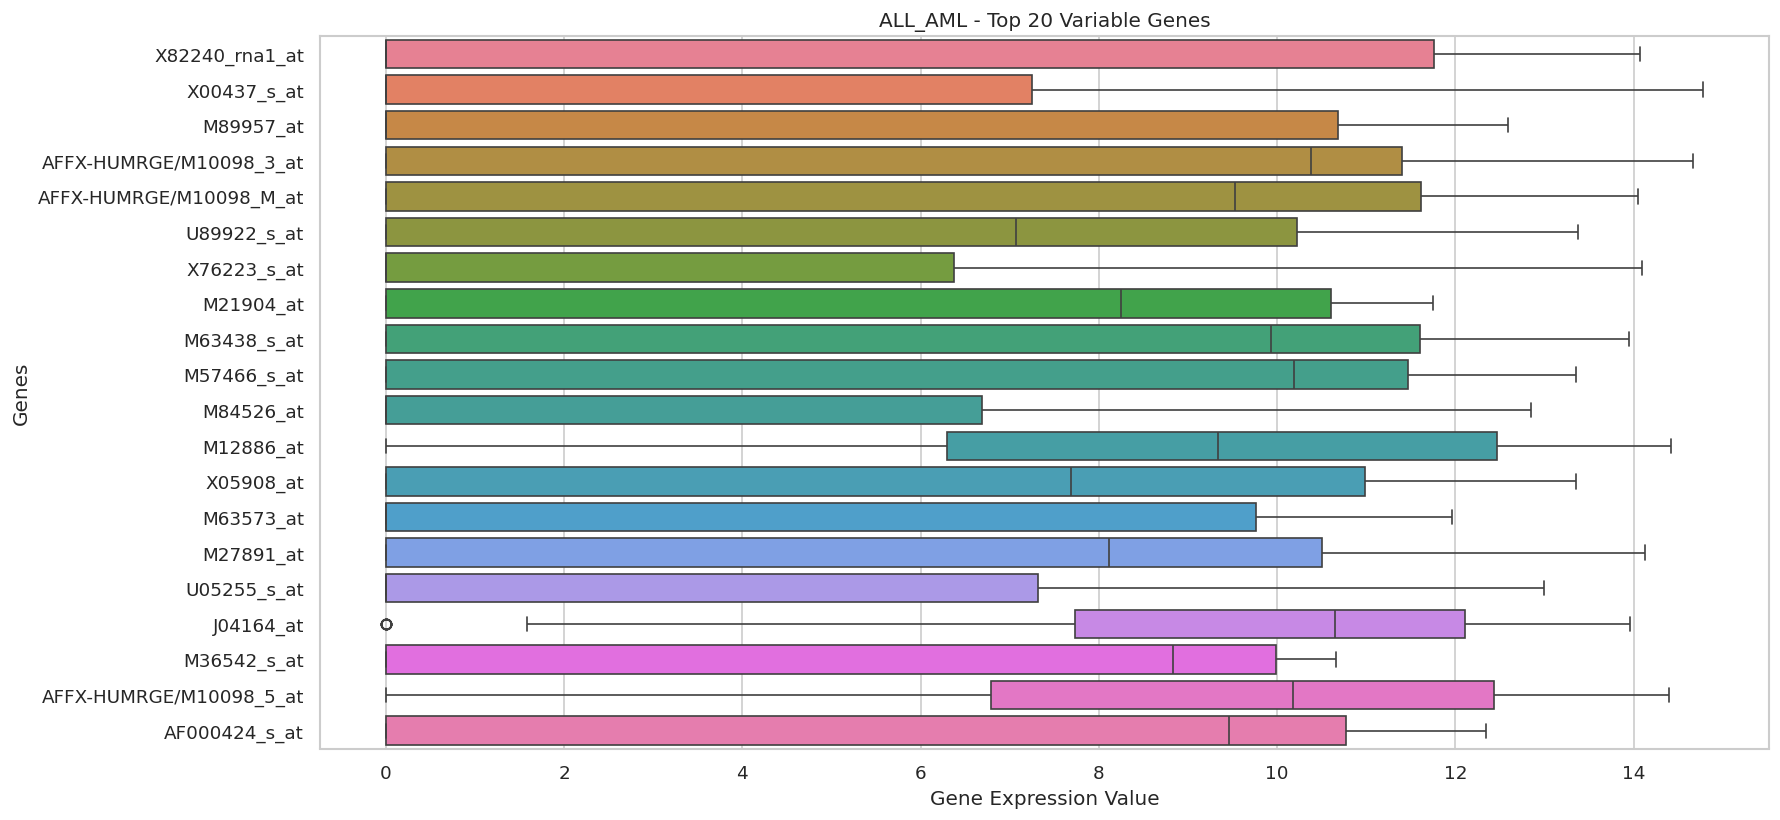

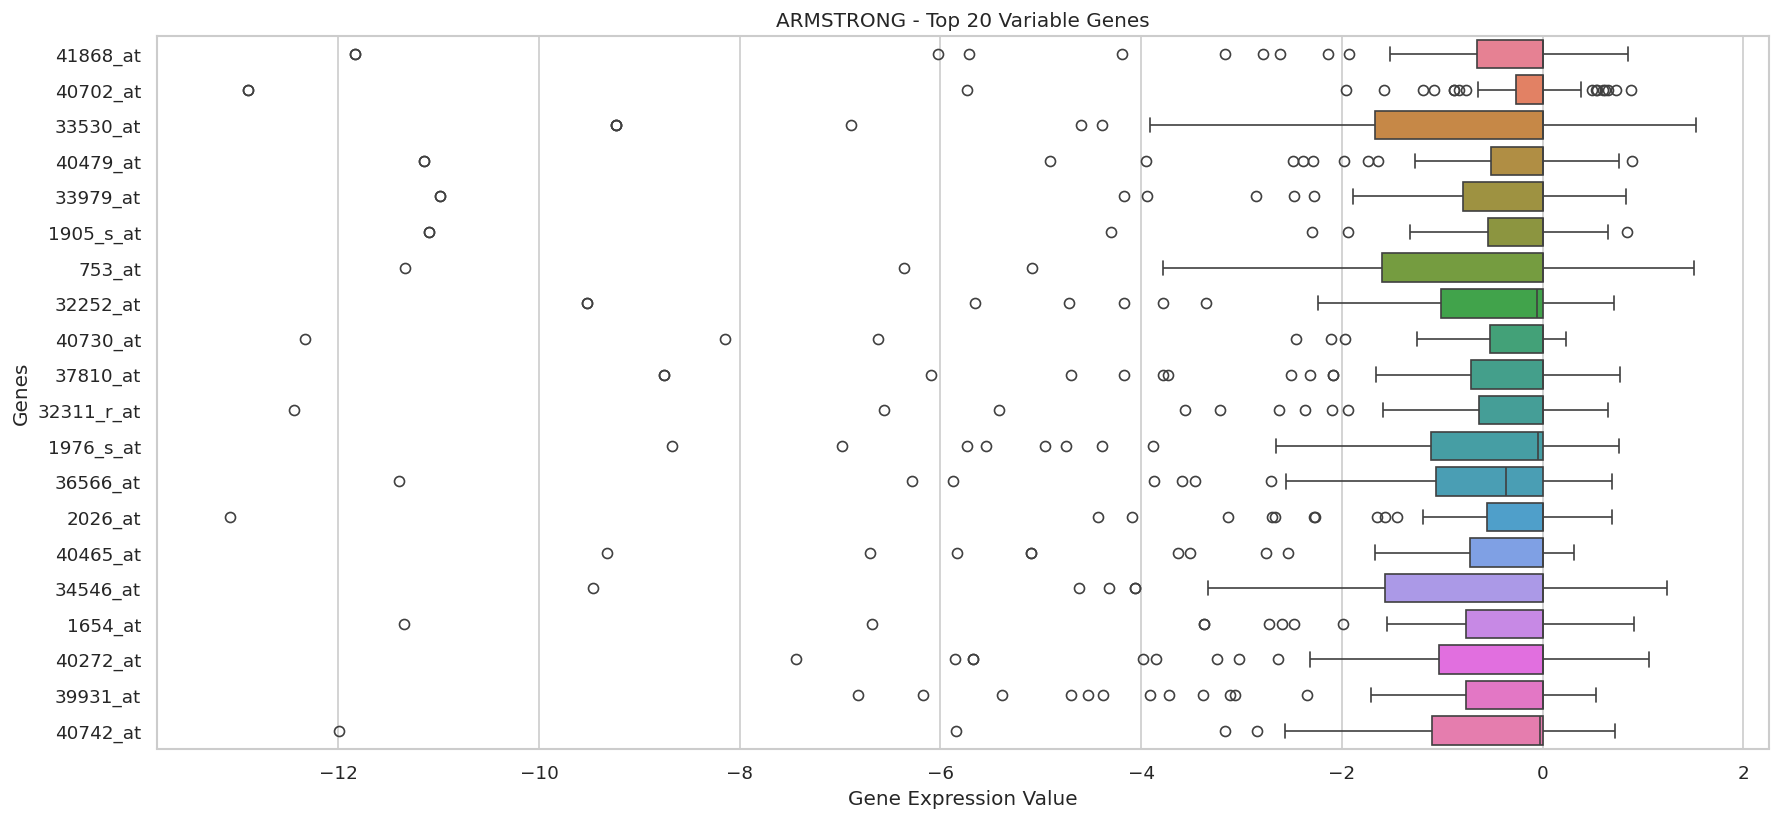

In [68]:
def outlier_boxplot(X, dataset_name):

    # En yüksek varyansa sahip 20 geni seç
    top_genes = X.var().sort_values(
        ascending=False
    ).head(20).index

    plt.figure(figsize=(15, 7))

    sns.boxplot(
        data=X[top_genes],
        orient="h",
        showfliers=True
    )

    plt.title(
        f"{dataset_name} - Top 20 Variable Genes"
    )

    plt.xlabel("Gene Expression Value")
    plt.ylabel("Genes")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_boxplot.png",
        dpi=300
    )

    plt.show()


outlier_boxplot(X_all, "ALL_AML")

outlier_boxplot(X_arm2, "ARMSTRONG")

,Sample,Outlier_Count,Outlier_Percentage
20,21,1043,14.630383
33,29,821,11.516342
11,12,653,9.159770
19,20,570,7.995511
26,27,484,6.789171
21,22,456,6.396409
16,17,454,6.368355
28,35,441,6.186001
5,6,422,5.919484
34,30,410,5.751157


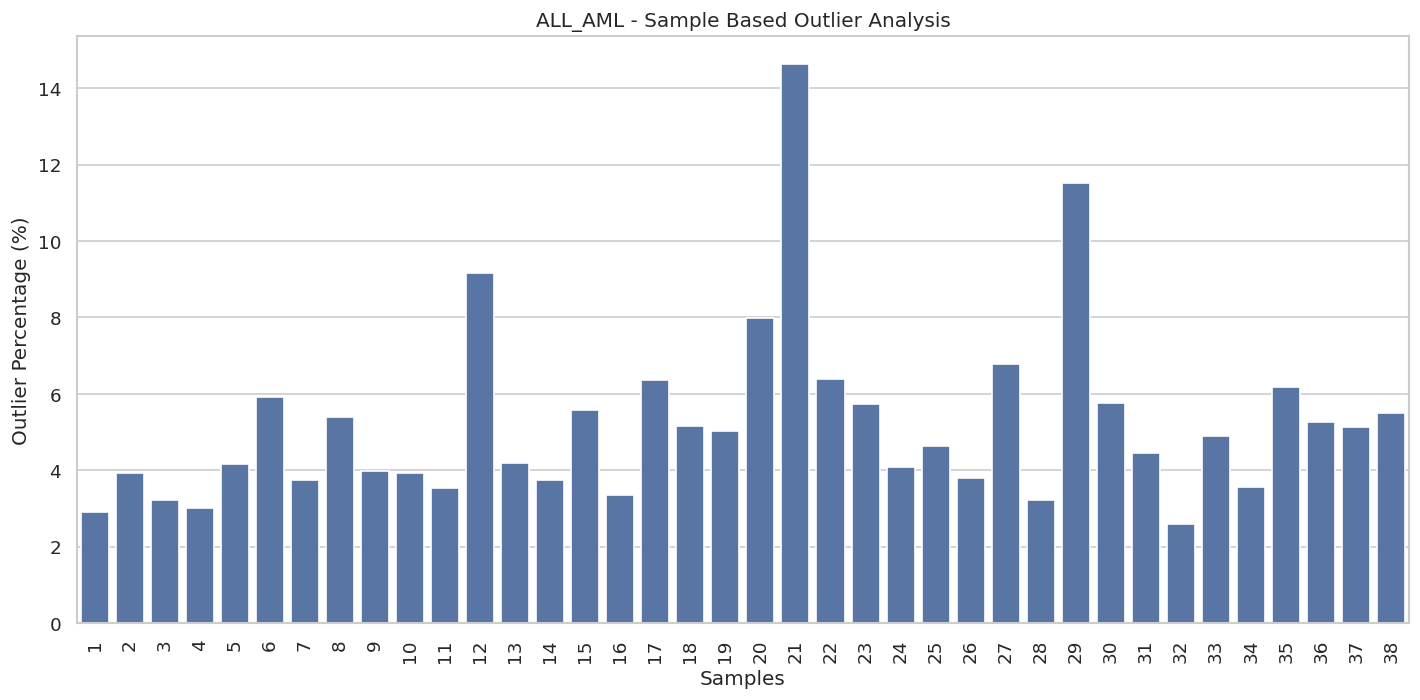

,Sample,Outlier_Count,Outlier_Percentage
1,ARM2_2,650,29.626253
6,ARM2_7,649,29.580675
24,ARM2_25,637,29.033728
0,ARM2_1,626,28.532361
21,ARM2_22,610,27.803099
40,ARM2_41,607,27.666363
25,ARM2_26,606,27.620784
7,ARM2_8,606,27.620784
18,ARM2_19,597,27.210574
10,ARM2_11,585,26.663628


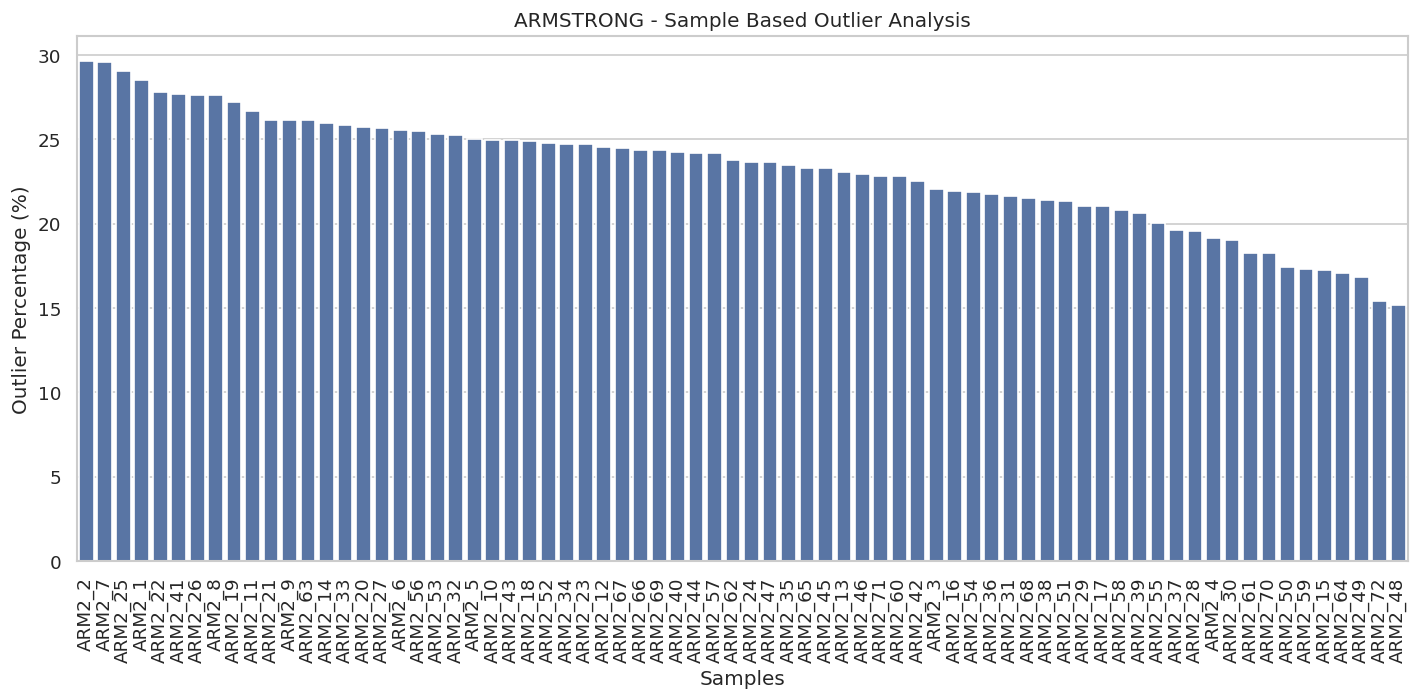

In [69]:
def sample_outlier_analysis(X, dataset_name):

    Q1 = X.quantile(0.25)

    Q3 = X.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        X.lt(lower, axis=1) |
        X.gt(upper, axis=1)
    )

    # Her örnekteki uç değer sayısı
    sample_outliers = outlier_mask.sum(axis=1)

    results = pd.DataFrame({
        "Sample": X.index,
        "Outlier_Count": sample_outliers.values,
        "Outlier_Percentage": (
            sample_outliers.values / X.shape[1]
        ) * 100
    })

    results = results.sort_values(
        "Outlier_Count",
        ascending=False
    )

    display(results.head(15))

    results.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_sample_outliers.csv",
        index=False
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=results,
        x="Sample",
        y="Outlier_Percentage"
    )

    plt.xticks(rotation=90)

    plt.title(
        f"{dataset_name} - Sample Based Outlier Analysis"
    )

    plt.xlabel("Samples")

    plt.ylabel("Outlier Percentage (%)")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_sample_outliers.png",
        dpi=300
    )

    plt.show()

    return results


all_sample_outliers = sample_outlier_analysis(
    X_all,
    "ALL_AML"
)

arm_sample_outliers = sample_outlier_analysis(
    X_arm2,
    "ARMSTRONG"
)

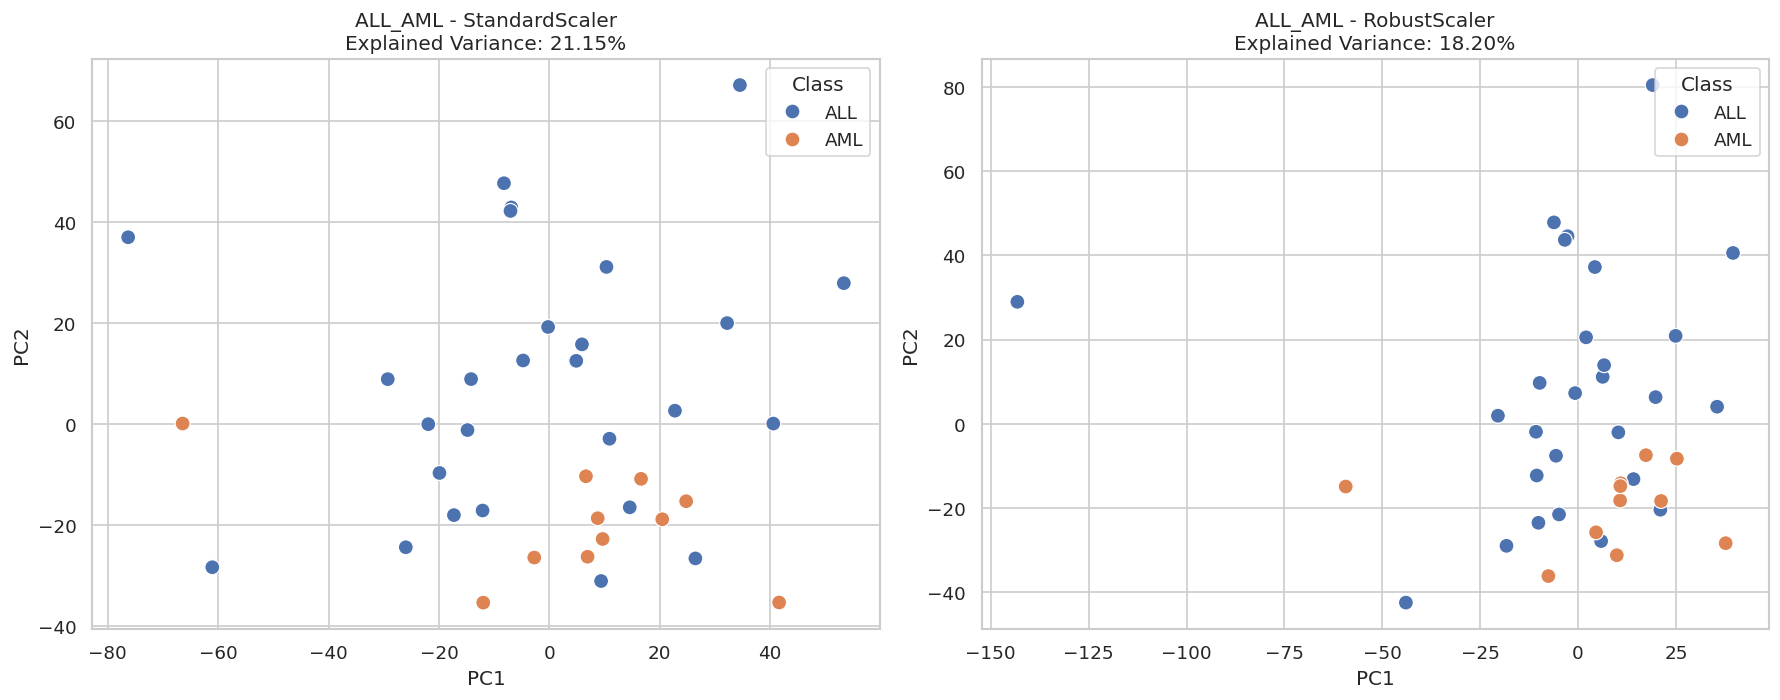

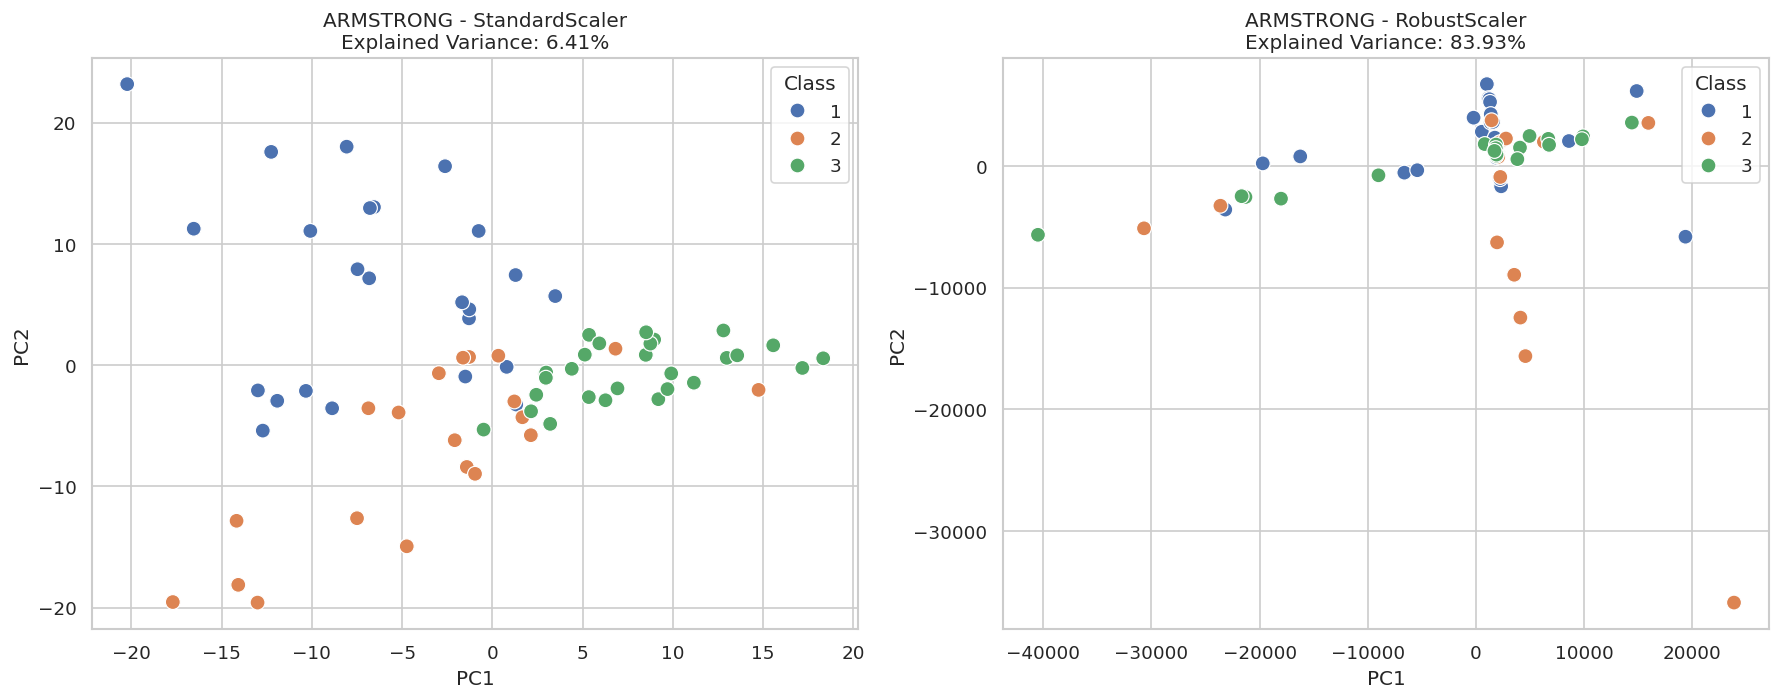

In [70]:
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer


def compare_scalers(X, y, dataset_name):

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X = X.dropna(axis=1, how="all")

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(X)

    scalers = {
        "StandardScaler": StandardScaler(),
        "RobustScaler": RobustScaler()
    }

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6)
    )

    for ax, (name, scaler) in zip(
        axes,
        scalers.items()
    ):

        X_scaled = scaler.fit_transform(
            X_imputed
        )

        pca = PCA(
            n_components=2
        )

        components = pca.fit_transform(
            X_scaled
        )

        result = pd.DataFrame({
            "PC1": components[:, 0],
            "PC2": components[:, 1],
            "Class": np.asarray(y).astype(str)
        })

        sns.scatterplot(
            data=result,
            x="PC1",
            y="PC2",
            hue="Class",
            ax=ax,
            s=80
        )

        ax.set_title(
            f"{dataset_name} - {name}\n"
            f"Explained Variance: "
            f"{pca.explained_variance_ratio_.sum()*100:.2f}%"
        )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_scaler_comparison.png",
        dpi=300
    )

    plt.show()


compare_scalers(
    X_all,
    y_all,
    "ALL_AML"
)

compare_scalers(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

ALL_AML_TRAIN P/A/M dağılımı:


,Count
P,78632
A,187892
M,4378


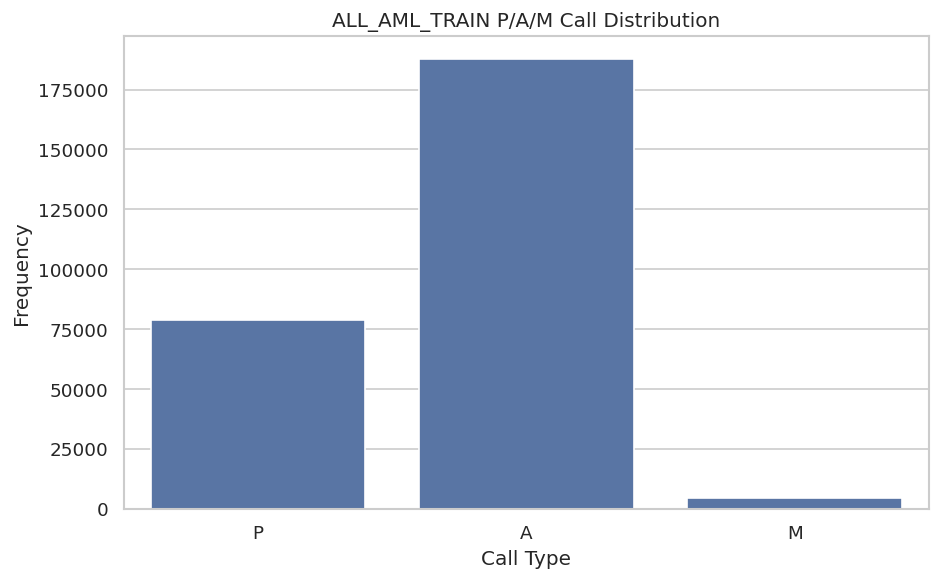

ALL_AML_INDEPENDENT P/A/M dağılımı:


,Count
P,66244
A,172247
M,3895


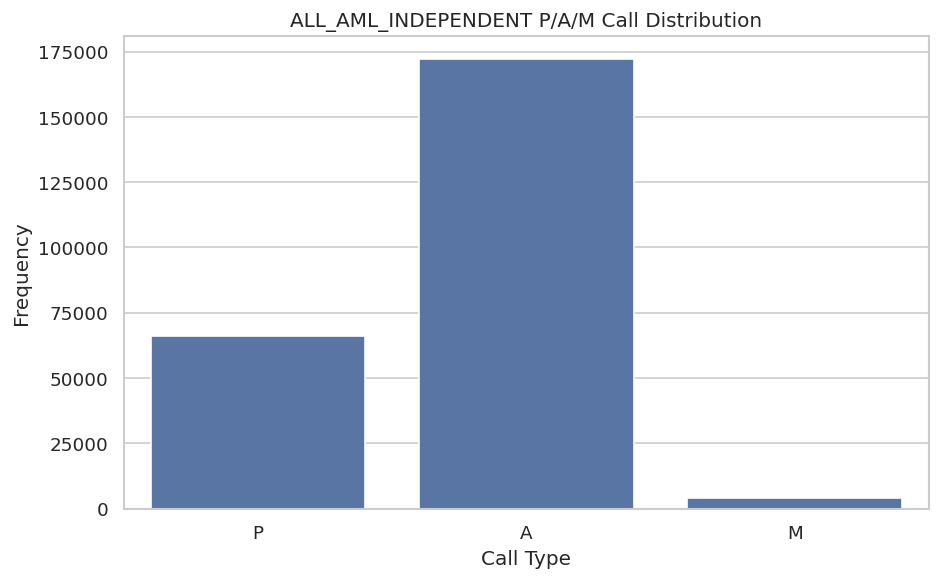

In [71]:
def analyze_calls(df, dataset_name):

    call_columns = [
        c for c in df.columns
        if str(c).lower() == "call"
        or str(c).lower().startswith("call.")
    ]

    if not call_columns:
        print("P/A/M sütunları bulunamadı.")
        return None

    calls = df[call_columns].copy()

    calls = calls.astype(str).apply(
        lambda col: col.str.strip().str.upper()
    )

    counts = calls.stack().value_counts()

    counts = counts.reindex(
        ["P", "A", "M"],
        fill_value=0
    )

    print(dataset_name, "P/A/M dağılımı:")
    display(counts.to_frame("Count"))

    counts.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_PAM.csv"
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=counts.index,
        y=counts.values
    )

    plt.title(f"{dataset_name} P/A/M Call Distribution")
    plt.xlabel("Call Type")
    plt.ylabel("Frequency")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PAM.png",
        dpi=300
    )

    plt.show()

    return counts


pam_train = analyze_calls(
    all_raw,
    "ALL_AML_TRAIN"
)

pam_test = analyze_calls(
    independent_raw,
    "ALL_AML_INDEPENDENT"
)

In [72]:
def descriptive_analysis(X, dataset_name):

    stats = X.describe(
        percentiles=[
            0.01,
            0.25,
            0.50,
            0.75,
            0.99
        ]
    )

    stats.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_statistics.csv"
    )

    display(stats)

    return stats


stats_all = descriptive_analysis(
    X_all,
    "ALL_AML_TRAIN"
)

stats_test = descriptive_analysis(
    X_independent,
    "ALL_AML_INDEPENDENT"
)

stats_arm2 = descriptive_analysis(
    X_arm2,
    "ARMSTRONG"
)

Gene Accession Number,A28102_at,AB000114_at,AB000115_at,AB000220_at,AB000381_s_at,AB000409_at,AB000410_s_at,AB000449_at,AB000450_at,AB000460_at,...,Z84721_cds2_at,Z84722_at,Z86000_at,Z93784_at,Z94753_s_at,Z95624_at,Z96810_at,Z97054_xpt2_at,Z97074_at,hum_alu_at
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,...,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,7.713202,-inf,7.734579,4.524015,4.732460,3.516182,0.307906,7.538837,7.037858,10.841821,...,12.798135,0.182698,9.242745,8.316329,6.430048,6.581461,-inf,8.939981,6.582375,14.216087
std,1.197211,NaN,1.080359,1.900654,2.492323,3.505253,1.324329,1.108172,1.113649,0.362358,...,1.821706,1.126225,0.532263,0.988220,1.423514,0.771137,NaN,0.567167,2.329081,0.524472
min,4.321928,-inf,6.149747,0.000000,0.000000,0.000000,0.000000,4.807355,4.247928,9.930737,...,6.209453,0.000000,8.164907,5.392317,0.000000,4.321928,-inf,7.312883,0.000000,12.661555
1%,4.766533,NaN,6.171838,0.000000,0.000000,0.000000,0.000000,4.941506,4.349912,10.078804,...,6.561108,0.000000,8.247458,5.781049,1.326436,4.589241,NaN,7.528199,0.000000,12.945951
25%,6.968658,0.000000,7.246478,3.837312,3.637055,0.000000,0.000000,6.921614,6.596061,10.538842,...,12.497938,0.000000,8.835255,7.632873,5.980374,6.027874,0.000000,8.649094,6.845490,13.910015
50%,7.994076,4.988640,7.622052,5.227664,5.672148,4.183161,0.000000,7.560949,7.404834,10.817290,...,13.290208,0.000000,9.193142,8.569536,6.813767,6.650891,0.000000,9.001391,7.189825,14.155987
75%,8.594292,5.899892,8.092266,5.417778,6.437282,6.839196,0.000000,8.276102,7.754462,11.053413,...,13.831331,0.000000,9.641045,8.915118,7.169820,7.187191,0.000000,9.356976,7.746008,14.537173
99%,9.602235,7.377765,10.916959,7.494271,7.181200,8.690572,5.889163,9.828528,9.049306,11.585342,...,14.718623,4.373784,10.367300,9.948554,7.956794,7.795068,5.975280,9.950687,9.026205,15.354555
max,9.768184,7.442943,11.099348,7.584963,7.199672,8.768184,6.000000,9.923327,9.118941,11.631177,...,14.852725,6.942515,10.436712,9.987264,8.103288,7.826548,6.169925,10.004220,9.147205,15.473325


Gene Accession Number,A28102_at,AB000114_at,AB000115_at,AB000220_at,AB000381_s_at,AB000409_at,AB000410_s_at,AB000449_at,AB000450_at,AB000460_at,...,Z84721_cds2_at,Z84722_at,Z86000_at,Z93784_at,Z94753_s_at,Z95624_at,Z96810_at,Z97054_xpt2_at,Z97074_at,hum_alu_at
count,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.0,34.000000,34.000000,34.000000,...,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000
mean,7.835452,-inf,7.614004,4.925918,3.961669,-inf,0.0,6.895405,7.234886,10.676661,...,12.818097,0.141393,9.053840,7.428785,5.810492,6.512445,1.691429,8.783902,5.102590,14.805614
std,0.961965,NaN,1.090007,2.125428,2.563171,NaN,0.0,1.698009,1.336552,0.537508,...,2.903333,0.824455,0.968362,1.414929,2.004086,0.635314,2.369386,0.829498,3.495816,0.558703
min,5.882643,-inf,6.022368,0.000000,0.000000,-inf,0.0,0.000000,1.000000,9.479780,...,0.000000,0.000000,4.857981,1.000000,0.000000,4.700440,0.000000,6.584963,0.000000,13.450567
1%,5.928752,NaN,6.029636,0.000000,0.000000,NaN,0.0,1.376075,2.642502,9.524914,...,2.237849,0.000000,5.858133,2.657381,0.000000,4.928759,0.000000,6.718191,0.000000,13.611244
25%,7.126371,0.000000,6.962818,4.739825,2.000000,0.000000,0.0,6.181925,6.832725,10.353337,...,12.442465,0.000000,8.799588,7.063031,5.465939,6.016522,0.000000,8.393191,0.000000,14.359847
50%,7.991185,4.906089,7.325245,5.507708,4.975642,1.660964,0.0,7.179360,7.396293,10.653281,...,13.578683,0.000000,9.282486,7.661422,6.285284,6.754640,0.000000,8.779225,6.679051,14.828227
75%,8.565993,6.033296,7.975846,6.087463,5.850704,6.954054,0.0,8.014012,7.952994,10.958001,...,14.374775,0.000000,9.486707,8.034781,6.940117,6.991446,3.127444,9.202124,7.731015,15.268986
99%,9.782854,7.818557,10.370707,7.567624,7.087072,9.386569,0.0,9.331007,8.898955,11.697302,...,15.279045,3.220928,10.515396,9.690958,8.009881,7.315897,6.756008,10.264815,9.197700,15.750917
max,10.111136,7.960002,10.472691,7.658211,7.118941,9.722808,0.0,9.702173,9.014020,11.801708,...,15.406537,4.807355,10.580259,9.845490,8.219169,7.330917,6.832890,10.280771,9.451211,15.828806


,AFFX-MurIL10_at,AFFX-PheX-3_at,AFFX-HUMISGF3A/M97935_5_at,AFFX-HUMISGF3A/M97935_MA_at,AFFX-HUMRGE/M10098_5_at,AFFX-HUMRGE/M10098_M_at,AFFX-HUMTFRR/M11507_M_at,AFFX-M27830_5_at,31312_at,31314_at,...,112_g_at,115_at,118_at,120_at,122_at,123_at,135_g_at,101_at,103_at,107_at
count,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,...,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000
mean,-0.345729,-0.048501,-0.269496,-0.702409,-0.022854,0.112813,-0.332410,-0.791173,-0.121987,-0.199540,...,-0.350982,-0.290166,-0.002727,-0.503370,-0.030435,-0.360124,-0.114891,-0.015292,-0.498990,-0.465116
std,1.138860,0.422872,0.939401,1.320503,0.471148,0.442146,1.047066,1.408770,0.769702,0.700459,...,0.962425,0.970094,0.692306,1.347703,0.406286,0.948822,0.654385,0.651799,1.200170,0.952494
min,-6.060516,-1.763572,-3.997622,-5.066765,-1.306464,-0.236733,-5.257502,-4.742468,-5.754975,-2.988388,...,-3.524754,-3.515037,-3.628440,-6.452985,-1.666669,-3.981719,-3.033135,-3.972248,-5.818739,-4.254543
1%,-6.060516,-1.567740,-3.848277,-4.696251,-1.185620,-0.095476,-3.917226,-4.543065,-2.818884,-2.537889,...,-3.340114,-3.335069,-2.730679,-6.452985,-1.211735,-3.463264,-2.470753,-2.892076,-5.348846,-3.682710
25%,-0.395013,0.000000,-0.204572,-1.169837,-0.003318,0.000000,-0.341166,-1.640798,-0.007518,-0.022218,...,-0.275338,-0.277164,0.000000,-0.702826,0.000000,-0.347681,-0.034860,0.000000,-0.759160,-0.499852
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001601,...,0.000000,0.000000,0.022018,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
99%,0.680651,0.746499,1.047027,0.802982,1.289579,2.059900,0.950717,1.210156,0.632175,0.747105,...,0.794469,1.412058,1.272480,0.939554,0.755823,0.703641,1.058933,0.990068,0.914014,0.468731
max,0.880858,0.879355,1.296473,0.917984,1.729034,2.450036,0.961757,1.257770,0.689338,0.842318,...,0.797064,1.445499,1.379976,1.067432,0.778871,0.888138,1.345875,1.011368,1.064089,0.636865


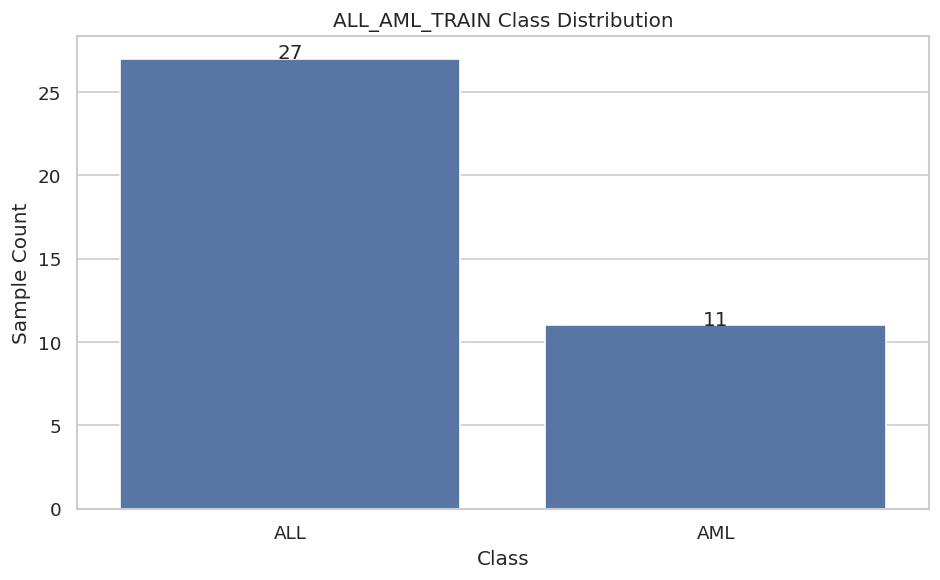

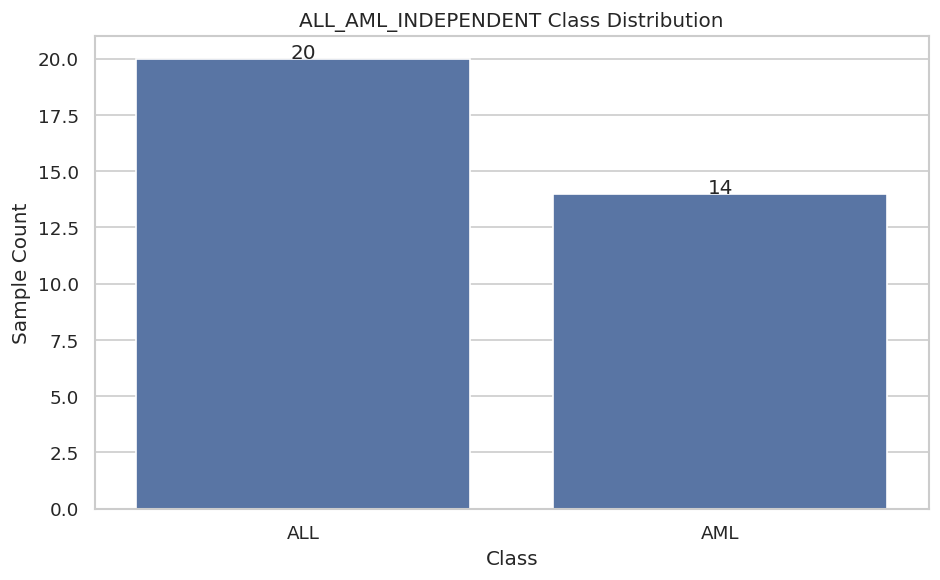

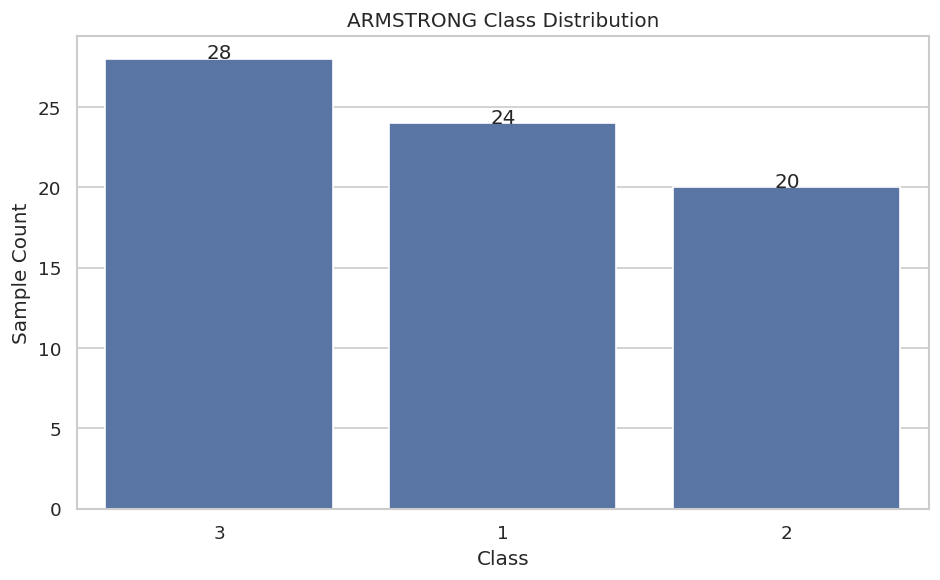

group
3    28
1    24
2    20
Name: count, dtype: int64

In [73]:
def class_distribution(y, dataset_name):

    counts = y.value_counts()

    plt.figure(figsize=(8, 5))

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values
    )

    plt.title(f"{dataset_name} Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Sample Count")

    for i, value in enumerate(counts.values):
        plt.text(i, value, str(value), ha="center")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_class_distribution.png",
        dpi=300
    )

    plt.show()

    return counts


class_distribution(y_all, "ALL_AML_TRAIN")
class_distribution(y_independent, "ALL_AML_INDEPENDENT")
class_distribution(y_arm2, "ARMSTRONG")

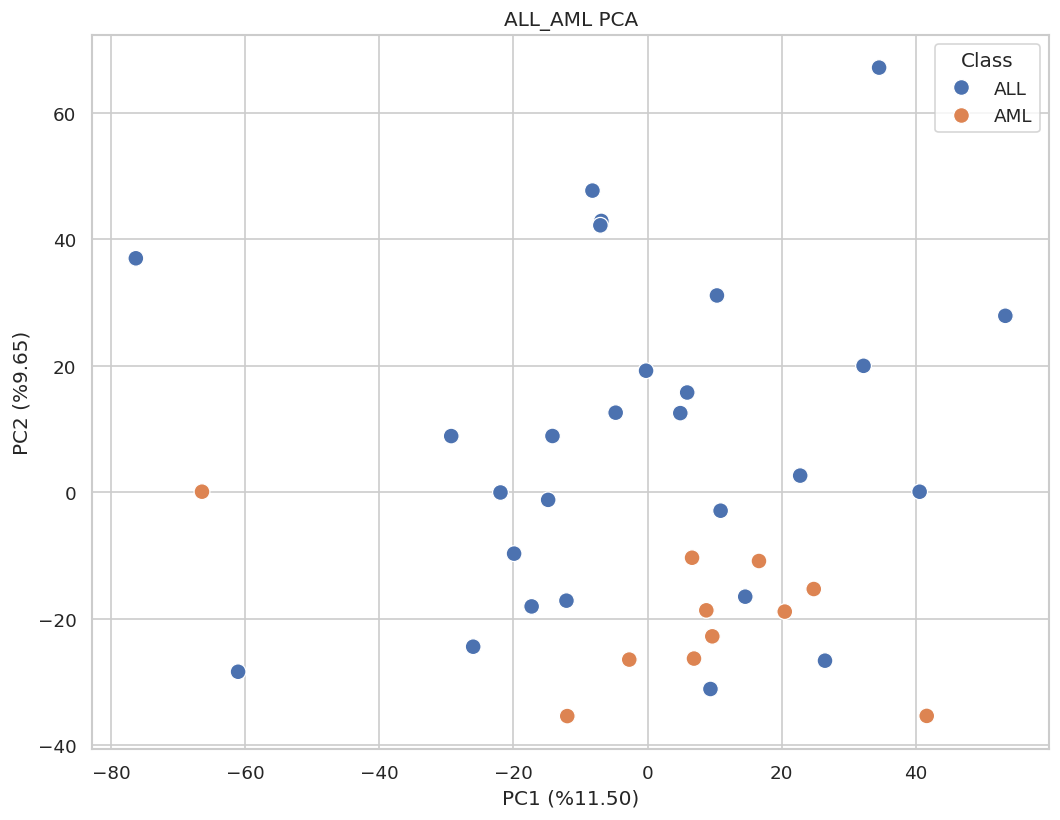

PC1: 0.1150291390671121
PC2: 0.09647065229464459
İlk iki bileşenin toplam varyansı: 0.21149979136175667


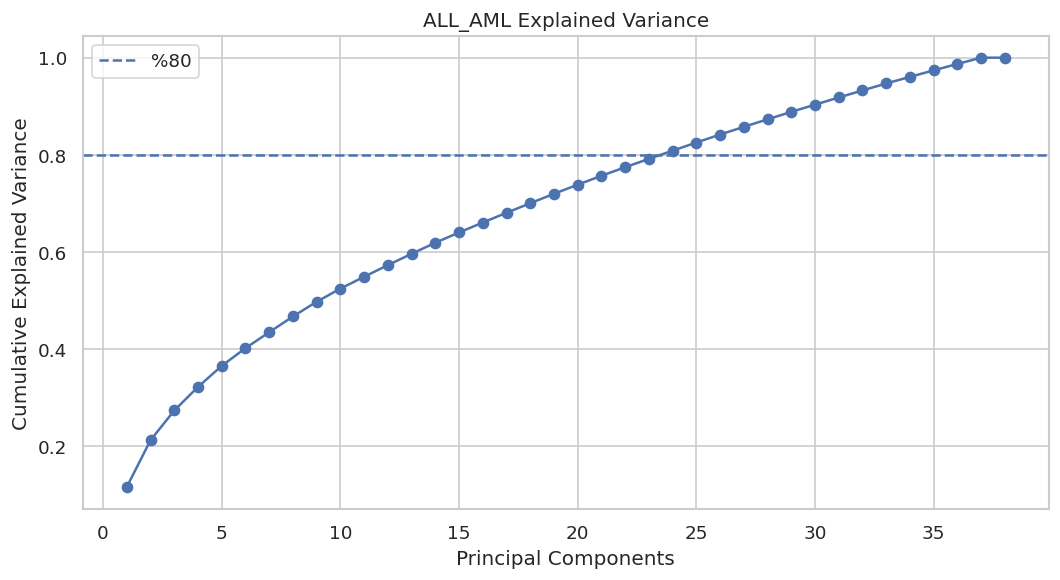

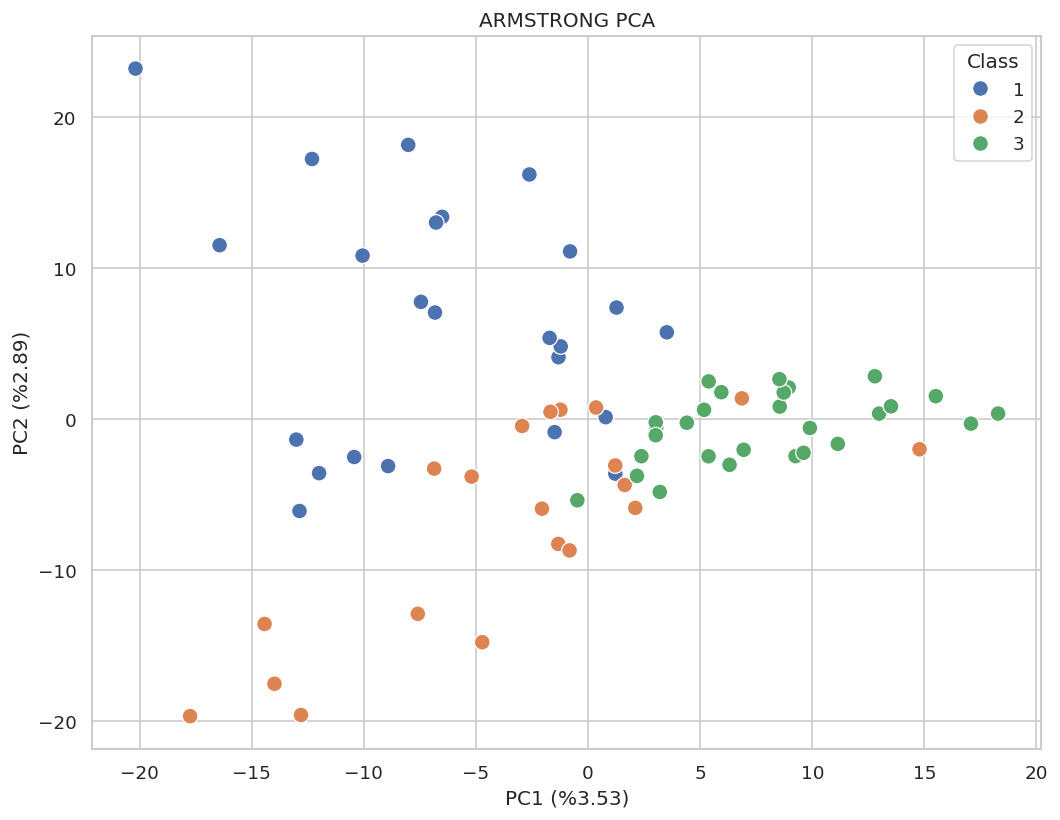

PC1: 0.035288671568016454
PC2: 0.028860141232058188
İlk iki bileşenin toplam varyansı: 0.06414881280007464


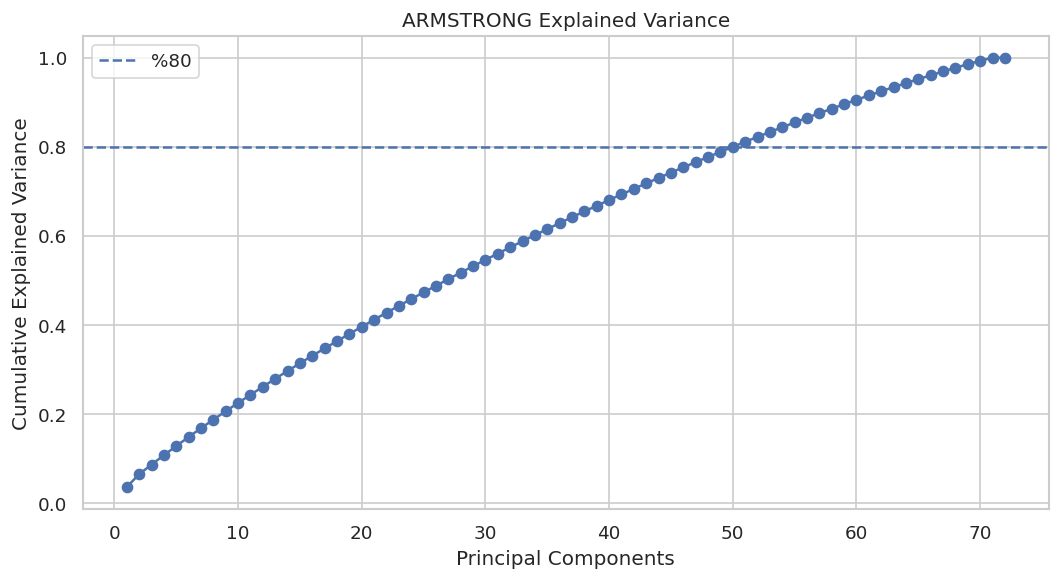

In [74]:
def prepare_for_analysis(X, fit_imputer=None):

    X = X.copy()

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Tamamen boş genleri çıkar
    X = X.dropna(axis=1, how="all")

    if fit_imputer is None:

        imputer = SimpleImputer(
            strategy="median"
        )

        transformed = imputer.fit_transform(X)

    else:

        imputer = fit_imputer

        transformed = imputer.transform(X)

    return transformed, imputer


def run_pca(X, y, dataset_name):

    values, imputer = prepare_for_analysis(X)

    scaler = StandardScaler()

    scaled = scaler.fit_transform(values)

    pca = PCA()

    components = pca.fit_transform(scaled)

    pca_df = pd.DataFrame({
        "PC1": components[:, 0],
        "PC2": components[:, 1],
        "Class": np.asarray(y).astype(str)
    }, index=X.index)

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="Class",
        s=90
    )

    plt.title(f"{dataset_name} PCA")

    plt.xlabel(
        f"PC1 (%{pca.explained_variance_ratio_[0]*100:.2f})"
    )

    plt.ylabel(
        f"PC2 (%{pca.explained_variance_ratio_[1]*100:.2f})"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PCA.png",
        dpi=300
    )

    plt.show()

    print("PC1:", pca.explained_variance_ratio_[0])
    print("PC2:", pca.explained_variance_ratio_[1])

    print(
        "İlk iki bileşenin toplam varyansı:",
        pca.explained_variance_ratio_[:2].sum()
    )

    # Açıklanan varyans grafiği
    cumulative = np.cumsum(
        pca.explained_variance_ratio_
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(cumulative)+1),
        cumulative,
        marker="o"
    )

    plt.axhline(
        0.80,
        linestyle="--",
        label="%80"
    )

    plt.xlabel("Principal Components")
    plt.ylabel("Cumulative Explained Variance")

    plt.title(f"{dataset_name} Explained Variance")

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_PCA_variance.png",
        dpi=300
    )

    plt.show()

    return pca_df, pca, scaler, imputer


all_pca, all_pca_model, all_scaler, all_imputer = run_pca(
    X_all, y_all, "ALL_AML"
)

arm_pca, arm_pca_model, arm_scaler, arm_imputer = run_pca(
    X_arm2, y_arm2, "ARMSTRONG"
)

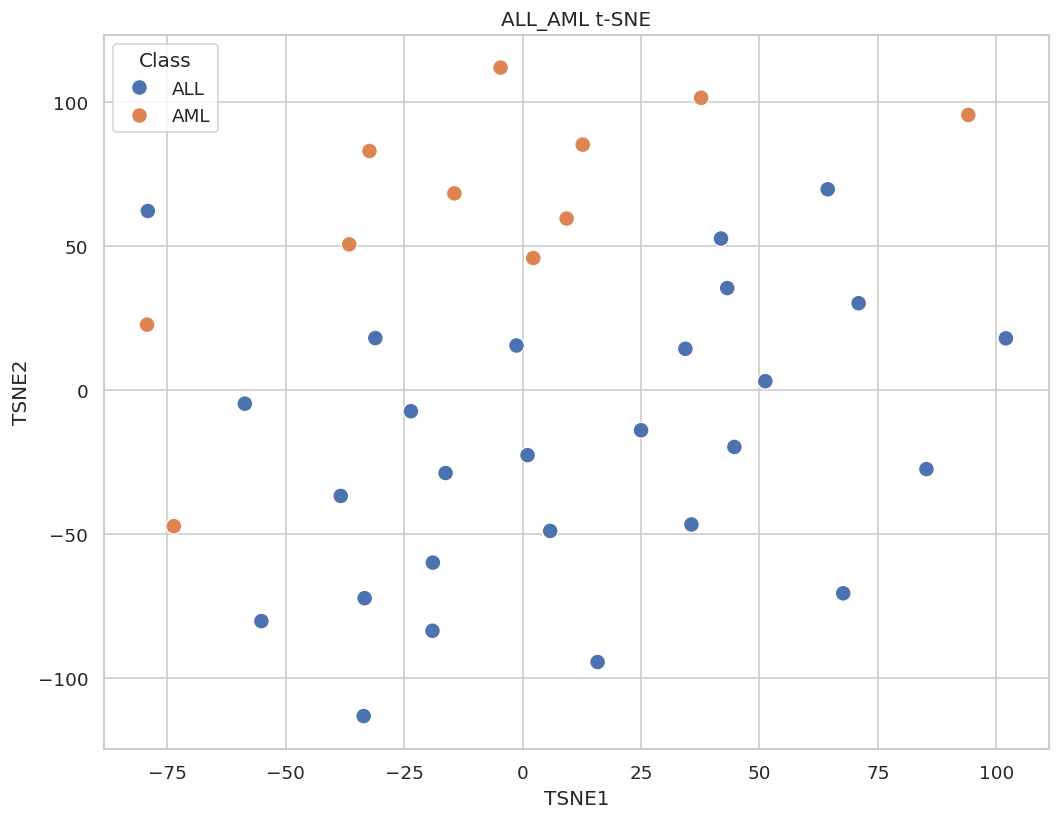

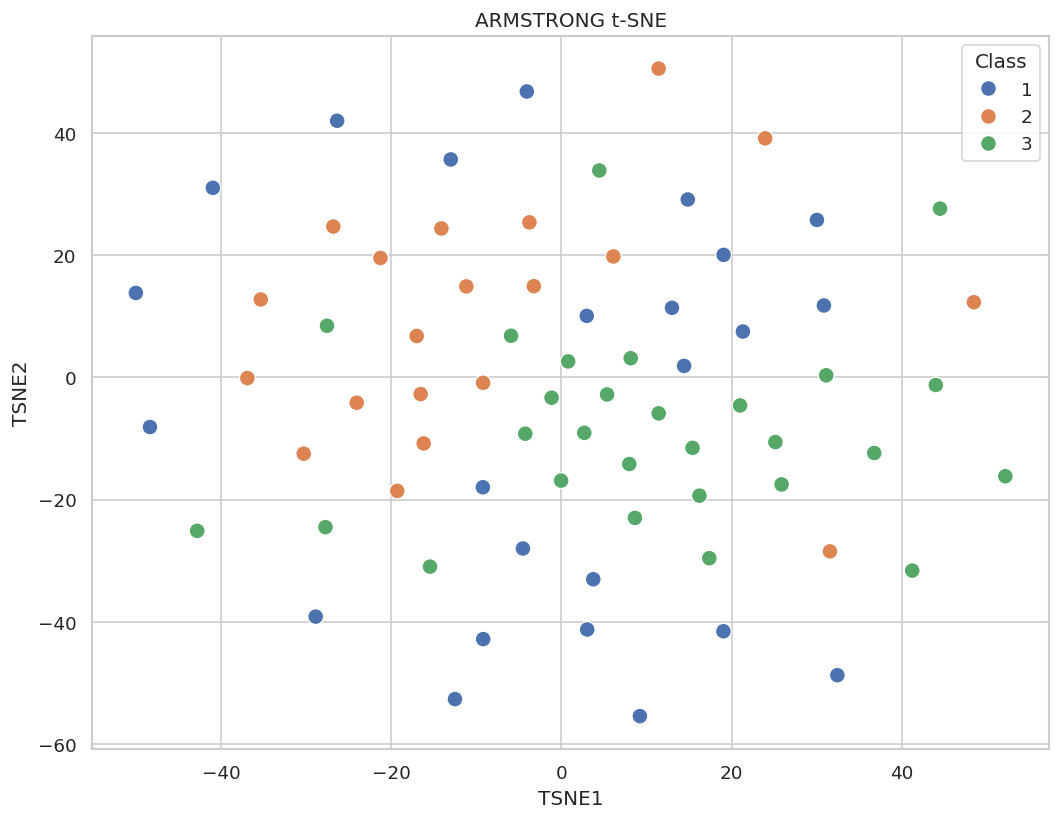

In [75]:
def run_tsne(X, y, dataset_name):

    values, imputer = prepare_for_analysis(X)

    scaled = StandardScaler().fit_transform(values)

    # Önce PCA ile boyut azalt
    n_components = min(
        30,
        scaled.shape[0] - 1,
        scaled.shape[1]
    )

    reduced = PCA(
        n_components=n_components,
        random_state=RANDOM_STATE
    ).fit_transform(scaled)

    perplexity = min(
        20,
        max(2, (len(X)-1)//3)
    )

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=RANDOM_STATE,
        init="pca",
        learning_rate="auto"
    )

    result = tsne.fit_transform(reduced)

    tsne_df = pd.DataFrame({
        "TSNE1": result[:, 0],
        "TSNE2": result[:, 1],
        "Class": np.asarray(y).astype(str)
    })

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=tsne_df,
        x="TSNE1",
        y="TSNE2",
        hue="Class",
        s=90
    )

    plt.title(f"{dataset_name} t-SNE")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_TSNE.png",
        dpi=300
    )

    plt.show()

    return tsne_df


all_tsne = run_tsne(
    X_all,
    y_all,
    "ALL_AML"
)

arm_tsne = run_tsne(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

In [76]:
def differential_gene_analysis(X, y, dataset_name):

    X = X.copy()

    y = pd.Series(
        np.asarray(y),
        index=X.index
    )

    classes = sorted(y.dropna().unique())

    results = []

    for gene in X.columns:

        groups = [
            X.loc[y == cls, gene].dropna().values
            for cls in classes
        ]

        if any(len(g) < 2 for g in groups):
            continue

        if len(classes) == 2:

            statistic, p_value = mannwhitneyu(
                groups[0],
                groups[1],
                alternative="two-sided"
            )

            test_name = "Mann-Whitney U"

        else:

            statistic, p_value = kruskal(*groups)

            test_name = "Kruskal-Wallis"

        row = {
            "Gene": gene,
            "Test": test_name,
            "Statistic": statistic,
            "P_Value": p_value
        }

        for cls, group_values in zip(classes, groups):

            row[f"Mean_{cls}"] = np.mean(group_values)

            row[f"Median_{cls}"] = np.median(group_values)

        results.append(row)

    result_df = pd.DataFrame(results)

    result_df["FDR"] = multipletests(
        result_df["P_Value"],
        method="fdr_bh"
    )[1]

    result_df = result_df.sort_values(
        "FDR"
    )

    result_df.to_csv(
        f"{OUTPUT_DIR}/{dataset_name}_differential_genes.csv",
        index=False
    )

    significant = result_df[
        result_df["FDR"] < 0.05
    ]

    print(dataset_name)

    print("Toplam test edilen gen:", len(result_df))

    print(
        "FDR < 0.05 gen sayısı:",
        len(significant)
    )

    display(result_df.head(30))

    return result_df


diff_all = differential_gene_analysis(
    X_all,
    y_all,
    "ALL_AML"
)

diff_arm2 = differential_gene_analysis(
    X_arm2,
    y_arm2,
    "ARMSTRONG"
)

ALL_AML
Toplam test edilen gen: 7129
FDR < 0.05 gen sayısı: 441


,Gene,Test,Statistic,P_Value,Mean_ALL,Median_ALL,Mean_AML,Median_AML,FDR
2848,M55150_at,Mann-Whitney U,7.0,0.000006,9.508845,9.649256,10.819556,10.775610,0.003674
901,D88422_at,Mann-Whitney U,6.0,0.000005,6.355729,6.977280,10.418987,9.984418,0.003674
6859,Y12670_at,Mann-Whitney U,7.0,0.000006,8.483384,8.396605,10.236522,10.083479,0.003674
6612,X95735_at,Mann-Whitney U,0.0,0.000002,6.998683,8.491853,11.395033,11.525031,0.003674
2537,M23197_at,Mann-Whitney U,6.0,0.000005,7.295573,7.247928,9.376729,9.596190,0.003674
2623,M27783_s_at,Mann-Whitney U,5.0,0.000004,4.518876,4.807355,10.058465,10.082149,0.003674
3208,M84526_at,Mann-Whitney U,30.0,0.000002,0.501387,0.000000,9.418936,12.158925,0.003674
2627,M27891_at,Mann-Whitney U,2.0,0.000002,4.539737,5.169925,12.231728,12.765286,0.003674
2388,M16038_at,Mann-Whitney U,7.0,0.000006,8.032231,8.344296,10.607925,10.709084,0.003674
6164,X70297_at,Mann-Whitney U,7.0,0.000006,7.560128,7.665336,9.273800,9.245553,0.003674


ARMSTRONG
Toplam test edilen gen: 2194
FDR < 0.05 gen sayısı: 197


,Gene,Test,Statistic,P_Value,Mean_1,Median_1,Mean_2,Median_2,Mean_3,Median_3,FDR
1585,38017_at,Kruskal-Wallis,46.993077,6.245726e-11,-0.382167,-0.238270,-0.520317,-0.428929,-0.008819,0.000000,1.370312e-07
1161,37539_at,Kruskal-Wallis,39.683282,2.414821e-09,0.474842,0.553815,-0.057552,0.000000,0.000000,0.000000,2.649058e-06
1016,35164_at,Kruskal-Wallis,38.650390,4.047385e-09,0.488038,0.521523,-0.022517,0.000000,0.000000,0.000000,2.751453e-06
681,39318_at,Kruskal-Wallis,38.221137,5.016323e-09,-0.162964,-0.167816,-0.291433,-0.167816,-0.052569,0.000000,2.751453e-06
1571,37680_at,Kruskal-Wallis,37.232337,8.224333e-09,0.451534,0.492297,-0.070768,0.000000,0.004207,0.000000,3.608837e-06
278,36392_at,Kruskal-Wallis,34.857167,2.696884e-08,0.507957,0.599890,-0.135663,0.000000,-0.019341,0.000000,9.861607e-06
196,34168_at,Kruskal-Wallis,32.115265,1.062329e-07,0.092741,0.151154,-0.840016,0.000000,-0.055319,0.000000,3.329642e-05
1337,40763_at,Kruskal-Wallis,31.555538,1.405406e-07,0.000000,0.000000,0.316080,0.323884,-0.643555,0.000000,3.854327e-05
1678,39878_at,Kruskal-Wallis,27.424928,1.108543e-06,0.214765,0.227166,-0.578086,-0.240465,-0.055952,0.000000,2.702381e-04
1407,32847_at,Kruskal-Wallis,27.057378,1.332187e-06,0.172656,0.522976,-0.517106,0.000000,0.000000,0.000000,2.922817e-04


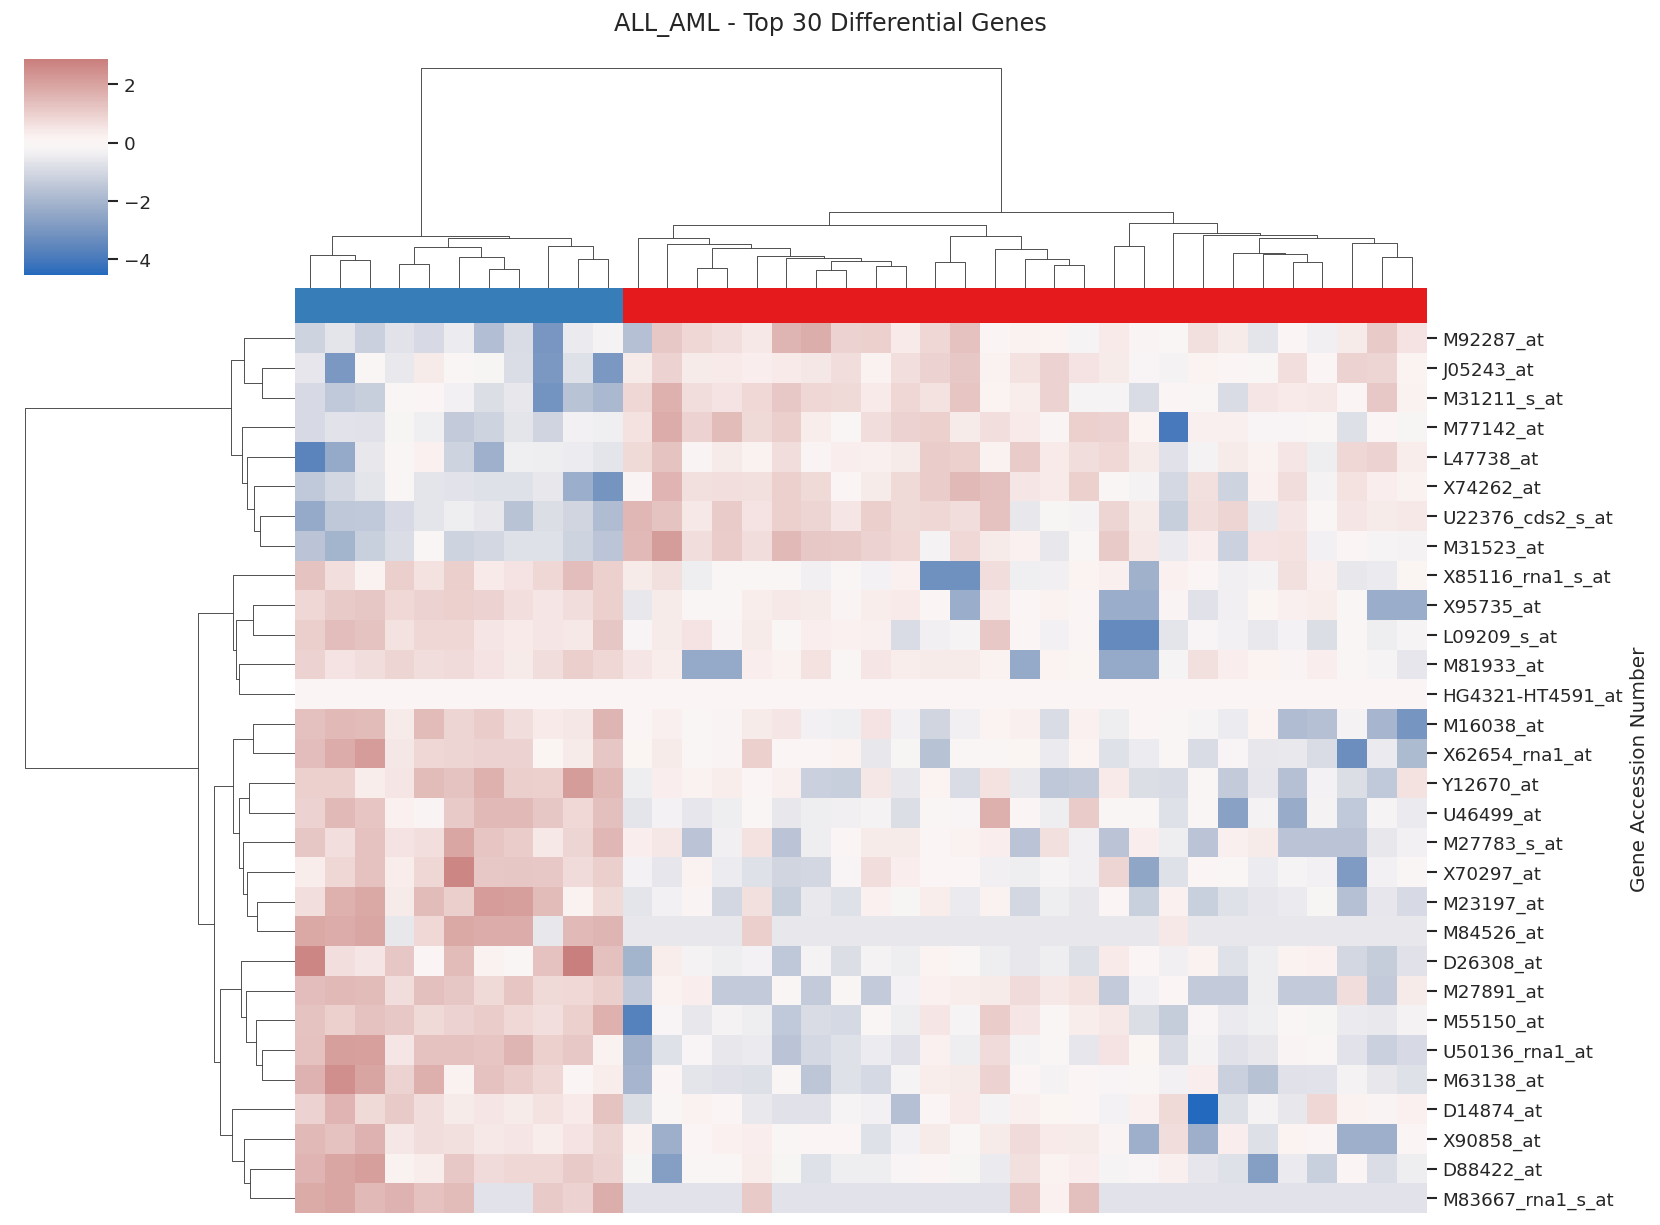

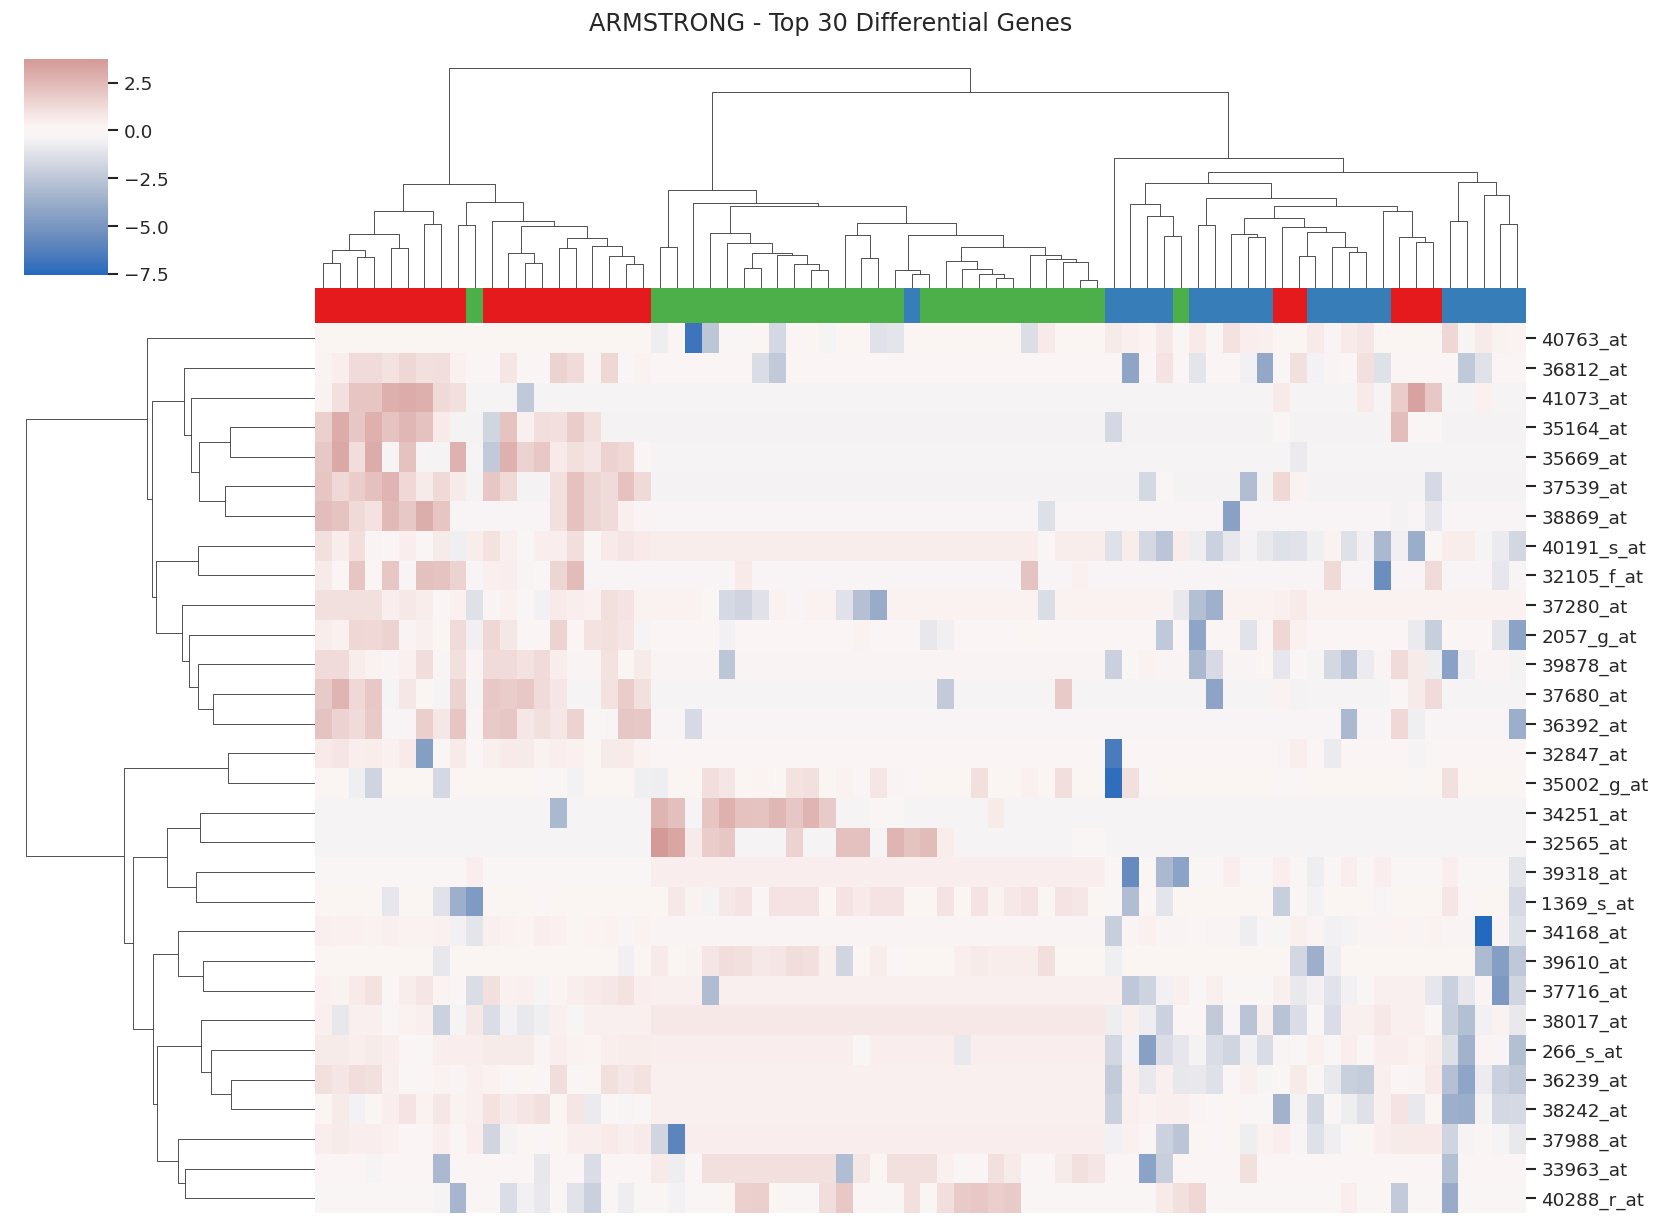

In [77]:
def gene_heatmap(X, y, diff_df, dataset_name):

    top_genes = (
        diff_df.head(TOP_N_GENES)["Gene"].tolist()
    )

    data = X[top_genes].copy()

    # Gen bazında Z-score standardizasyonu
    data = (
        data - data.mean()
    ) / data.std().replace(0, 1)

    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    # Sınıfları görselleştirme
    labels = np.asarray(y).astype(str)

    palette = sns.color_palette(
        "Set1",
        n_colors=len(np.unique(labels))
    )

    color_map = dict(
        zip(sorted(np.unique(labels)), palette)
    )

    sample_colors = pd.Series(labels).map(
        color_map
    )

    g = sns.clustermap(
        data.T,
        cmap="vlag",
        center=0,
        figsize=(14, 10),
        col_colors=sample_colors.tolist(),
        xticklabels=False,
        yticklabels=True,
        method="ward"
    )

    g.fig.suptitle(
        f"{dataset_name} - Top 30 Differential Genes",
        y=1.02
    )

    g.savefig(
        f"{OUTPUT_DIR}/{dataset_name}_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


gene_heatmap(
    X_all,
    y_all,
    diff_all,
    "ALL_AML"
)

gene_heatmap(
    X_arm2,
    y_arm2,
    diff_arm2,
    "ARMSTRONG"
)

Train gen sayısı: 7129
Test gen sayısı: 7129
Ortak gen sayısı: 7129

Infinity Kontrolü
Train infinity: 0
Test infinity: 0
Train eksik değer: 738
Test eksik değer: 877

Tamamen eksik genler çıkarıldı.
Kalan ortak gen sayısı: 7129

Imputation tamamlandı.
Standardizasyon tamamlandı.


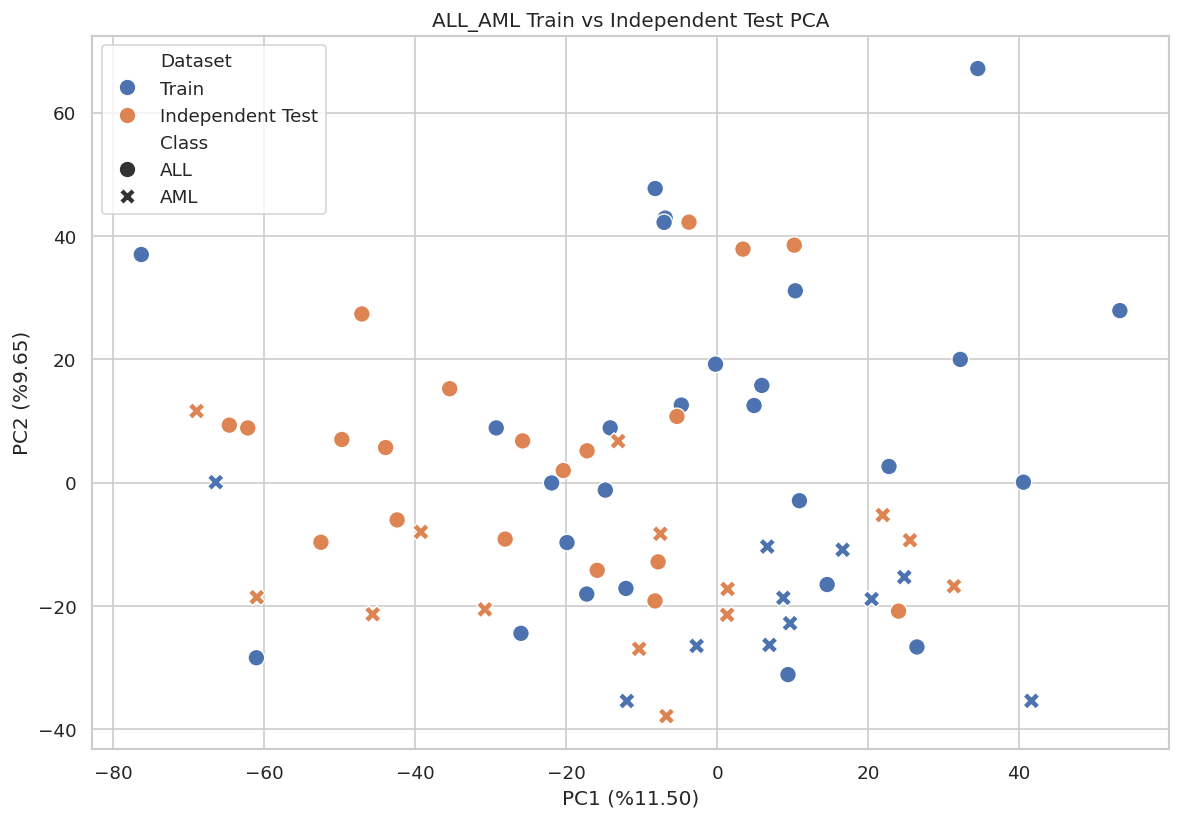


PC1 açıklanan varyans: 0.11502913906072368
PC2 açıklanan varyans: 0.09647065224052236
İlk iki bileşenin toplam açıklanan varyansı: 0.21149979130124602


In [79]:

# ============================================================
# 1. ORTAK GENLERİ BELİRLEME
# ============================================================

common_genes = X_all.columns.intersection(
    X_independent.columns
)

print("Train gen sayısı:", X_all.shape[1])
print("Test gen sayısı:", X_independent.shape[1])
print("Ortak gen sayısı:", len(common_genes))

if len(common_genes) < 2:
    raise ValueError("Ortak gen sayısı PCA için yetersiz.")

X_train_common = X_all[common_genes].copy()
X_test_common = X_independent[common_genes].copy()


# ============================================================
# 2. SAYISAL VERİ KONTROLÜ VE INFINITY TEMİZLİĞİ
# ============================================================

X_train_common = X_train_common.apply(
    pd.to_numeric, errors="coerce"
)

X_test_common = X_test_common.apply(
    pd.to_numeric, errors="coerce"
)

# Sonsuz değerleri NaN ile değiştir
X_train_common = X_train_common.replace(
    [np.inf, -np.inf], np.nan
)

X_test_common = X_test_common.replace(
    [np.inf, -np.inf], np.nan
)

print("\nInfinity Kontrolü")

print(
    "Train infinity:",
    np.isinf(X_train_common.to_numpy()).sum()
)

print(
    "Test infinity:",
    np.isinf(X_test_common.to_numpy()).sum()
)

print(
    "Train eksik değer:",
    X_train_common.isna().sum().sum()
)

print(
    "Test eksik değer:",
    X_test_common.isna().sum().sum()
)


# ============================================================
# 3. TAMAMEN EKSİK OLAN GENLERİ ÇIKARMA
# ============================================================

valid_genes = X_train_common.columns[
    X_train_common.notna().any()
]

X_train_common = X_train_common[valid_genes].copy()
X_test_common = X_test_common[valid_genes].copy()

print("\nTamamen eksik genler çıkarıldı.")

print("Kalan ortak gen sayısı:", len(valid_genes))

if len(valid_genes) < 2:
    raise ValueError("PCA için yeterli sayıda geçerli gen kalmadı.")


# ============================================================
# 4. SADECE TRAIN VERİSİNE GÖRE IMPUTATION
# ============================================================

imputer = SimpleImputer(
    strategy="median"
)

train_imputed = imputer.fit_transform(
    X_train_common
)

test_imputed = imputer.transform(
    X_test_common
)

print("\nImputation tamamlandı.")


# ============================================================
# 5. STANDARDİZASYON
# ============================================================

scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train_imputed
)

test_scaled = scaler.transform(
    test_imputed
)

print("Standardizasyon tamamlandı.")


# ============================================================
# 6. PCA
# ============================================================

if min(train_scaled.shape) < 2:
    raise ValueError("PCA için en az 2 bileşen oluşturulabilmelidir.")

pca = PCA(n_components=2)

train_components = pca.fit_transform(
    train_scaled
)

test_components = pca.transform(
    test_scaled
)


# ============================================================
# 7. SONUÇLARI BİRLEŞTİRME
# ============================================================

comparison_df = pd.DataFrame({

    "PC1": np.concatenate([
        train_components[:, 0],
        test_components[:, 0]
    ]),

    "PC2": np.concatenate([
        train_components[:, 1],
        test_components[:, 1]
    ]),

    "Dataset": (
        ["Train"] * len(X_train_common) +
        ["Independent Test"] * len(X_test_common)
    ),

    "Class": (
        y_all.astype(str).tolist() +
        y_independent.astype(str).tolist()
    )
})


# ============================================================
# 8. PCA GÖRSELLEŞTİRME
# ============================================================

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=comparison_df,
    x="PC1",
    y="PC2",
    hue="Dataset",
    style="Class",
    s=100
)

plt.title(
    "ALL_AML Train vs Independent Test PCA"
)

plt.xlabel(
    f"PC1 (%{pca.explained_variance_ratio_[0]*100:.2f})"
)

plt.ylabel(
    f"PC2 (%{pca.explained_variance_ratio_[1]*100:.2f})"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/ALL_AML_train_test_PCA.png",
    dpi=300
)

plt.show()


# ============================================================
# 9. AÇIKLANAN VARYANS
# ============================================================

print(
    "\nPC1 açıklanan varyans:",
    pca.explained_variance_ratio_[0]
)

print(
    "PC2 açıklanan varyans:",
    pca.explained_variance_ratio_[1]
)

print(
    "İlk iki bileşenin toplam açıklanan varyansı:",
    pca.explained_variance_ratio_.sum()
)


In [80]:
comparison = pd.DataFrame({

    "Train_Mean": X_train_common.mean(),

    "Test_Mean": X_test_common.mean(),

    "Train_Std": X_train_common.std(),

    "Test_Std": X_test_common.std()

})

comparison["Mean_Difference"] = (
    comparison["Train_Mean"] -
    comparison["Test_Mean"]
)

comparison["Std_Difference"] = (
    comparison["Train_Std"] -
    comparison["Test_Std"]
)

comparison.to_csv(
    f"{OUTPUT_DIR}/ALL_AML_train_test_comparison.csv"
)

display(
    comparison.sort_values(
        "Mean_Difference",
        key=abs,
        ascending=False
    ).head(20)
)

,Train_Mean,Test_Mean,Train_Std,Test_Std,Mean_Difference,Std_Difference
Gene Accession Number,,,,,,
M26602_at,2.046264,8.070728,3.855227,5.432584,-6.024464,-1.577358
AFFX-HUMRGE/M10098_M_at,7.373429,2.588161,5.384907,4.293764,4.785268,1.091142
AFFX-HUMRGE/M10098_3_at,7.531296,2.912249,5.395166,4.412407,4.619047,0.982759
AFFX-HUMRGE/M10098_5_at,8.935001,4.708998,4.850502,4.606895,4.226004,0.243606
X55668_at,1.968865,5.778240,3.698230,5.483577,-3.809375,-1.785347
HG4683-HT5108_s_at,3.355167,6.929248,3.762919,2.787299,-3.574082,0.975619
M26311_s_at,7.106954,10.524920,4.535335,3.343946,-3.417966,1.191389
M20203_s_at,2.252195,5.661435,4.264145,5.816871,-3.409239,-1.552726
M63573_at,4.394053,7.746540,5.000532,4.161459,-3.352487,0.839073


In [82]:
X_arm_train, X_arm_test, y_arm_train, y_arm_test = train_test_split(

    X_arm2,

    y_arm2,

    test_size=0.25,

    random_state=RANDOM_STATE,

    stratify=y_arm2
)

print("Armstrong Train:", X_arm_train.shape)
print("Armstrong Test:", X_arm_test.shape)

print("\nTrain sınıf dağılımı:")
print(y_arm_train.value_counts())

print("\nTest sınıf dağılımı:")
print(y_arm_test.value_counts())

Armstrong Train: (54, 2194)
Armstrong Test: (18, 2194)

Train sınıf dağılımı:
group
3    21
1    18
2    15
Name: count, dtype: int64

Test sınıf dağılımı:
group
3    7
1    6
2    5
Name: count, dtype: int64


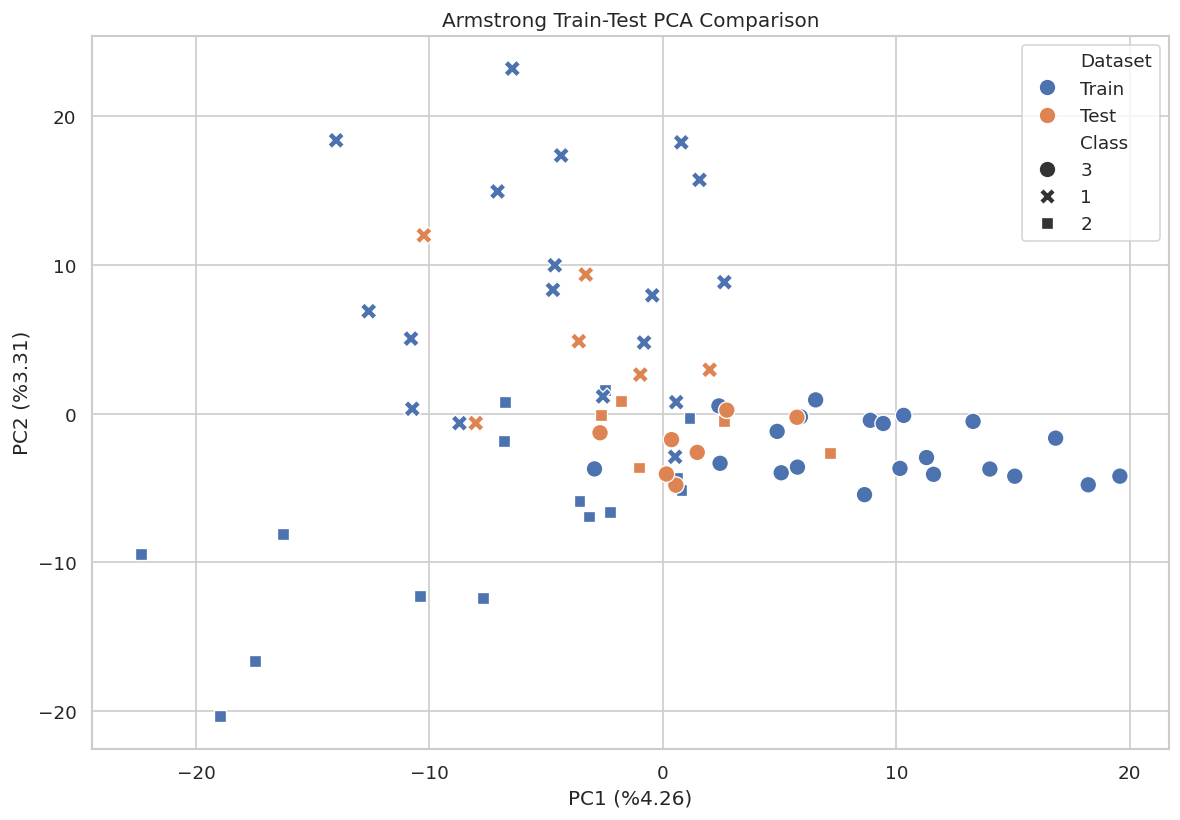

In [83]:
# Imputer yalnızca eğitim verisine fit edilir
imputer_arm = SimpleImputer(
    strategy="median"
)

arm_train_imp = imputer_arm.fit_transform(
    X_arm_train
)

arm_test_imp = imputer_arm.transform(
    X_arm_test
)

# StandardScaler yalnızca eğitim verisine fit edilir
scaler_arm = StandardScaler()

arm_train_scaled = scaler_arm.fit_transform(
    arm_train_imp
)

arm_test_scaled = scaler_arm.transform(
    arm_test_imp
)

# PCA yalnızca eğitim verisinde öğrenilir
pca_arm = PCA(n_components=2)

arm_train_pca = pca_arm.fit_transform(
    arm_train_scaled
)

arm_test_pca = pca_arm.transform(
    arm_test_scaled
)

arm_comparison = pd.DataFrame({

    "PC1": np.concatenate([
        arm_train_pca[:, 0],
        arm_test_pca[:, 0]
    ]),

    "PC2": np.concatenate([
        arm_train_pca[:, 1],
        arm_test_pca[:, 1]
    ]),

    "Dataset": (
        ["Train"] * len(X_arm_train) +
        ["Test"] * len(X_arm_test)
    ),

    "Class": (
        y_arm_train.astype(str).tolist() +
        y_arm_test.astype(str).tolist()
    )
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=arm_comparison,
    x="PC1",
    y="PC2",
    hue="Dataset",
    style="Class",
    s=100
)

plt.title("Armstrong Train-Test PCA Comparison")

plt.xlabel(
    f"PC1 (%{pca_arm.explained_variance_ratio_[0]*100:.2f})"
)

plt.ylabel(
    f"PC2 (%{pca_arm.explained_variance_ratio_[1]*100:.2f})"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/ARMSTRONG_train_test_PCA.png",
    dpi=300
)

plt.show()

In [84]:
common_genes = X_all.columns.intersection(
    X_arm2.columns
)

print("ALL_AML gen sayısı:", X_all.shape[1])

print("Armstrong gen sayısı:", X_arm2.shape[1])

print("Ortak gen kimliği sayısı:", len(common_genes))

if len(common_genes) >= 2:

    print("Ortak genler üzerinden karşılaştırma yapılabilir.")

    all_common = X_all[common_genes]

    arm_common = X_arm2[common_genes]

    comparison = pd.DataFrame({

        "ALL_AML_Mean": all_common.mean(),

        "Armstrong_Mean": arm_common.mean(),

        "ALL_AML_Std": all_common.std(),

        "Armstrong_Std": arm_common.std()

    })

    display(comparison.head(20))

    comparison.to_csv(
        f"{OUTPUT_DIR}/Cross_Dataset_Gene_Comparison.csv"
    )

else:

    print(
        "Ortak gen kimliği bulunamadı. "
        "Doğrudan gen bazlı karşılaştırma yapılamaz."
    )

    print(
        "Biyolojik anotasyon veya gen sembolleri üzerinden "
        "eşleştirme yapılmalıdır."
    )

ALL_AML gen sayısı: 7129
Armstrong gen sayısı: 2194
Ortak gen kimliği sayısı: 7
Ortak genler üzerinden karşılaştırma yapılabilir.


,ALL_AML_Mean,Armstrong_Mean,ALL_AML_Std,Armstrong_Std
AFFX-HUMISGF3A/M97935_5_at,0.312337,-0.269496,1.473895,0.939401
AFFX-HUMISGF3A/M97935_MA_at,1.706345,-0.702409,3.448520,1.320503
AFFX-HUMRGE/M10098_5_at,8.935001,-0.022854,4.850502,0.471148
AFFX-HUMRGE/M10098_M_at,7.373429,0.112813,5.384907,0.442146
AFFX-HUMTFRR/M11507_M_at,4.211350,-0.332410,3.471892,1.047066
AFFX-M27830_5_at,9.898903,-0.791173,2.924269,1.408770
AFFX-PheX-3_at,-inf,-0.048501,NaN,0.422872


In [85]:
# Betimsel istatistikler
stats_all.to_csv(
    f"{OUTPUT_DIR}/ALL_AML_statistics.csv"
)

stats_arm2.to_csv(
    f"{OUTPUT_DIR}/ARMSTRONG_statistics.csv"
)

# PCA varyans sonuçları
pca_results = pd.DataFrame({

    "Dataset": ["ALL_AML", "ARMSTRONG"],

    "PC1": [
        all_pca_model.explained_variance_ratio_[0],
        arm_pca_model.explained_variance_ratio_[0]
    ],

    "PC2": [
        all_pca_model.explained_variance_ratio_[1],
        arm_pca_model.explained_variance_ratio_[1]
    ]

})

pca_results["Total"] = (
    pca_results["PC1"] +
    pca_results["PC2"]
)

pca_results.to_csv(
    f"{OUTPUT_DIR}/PCA_results.csv",
    index=False
)

display(pca_results)

print("\nBütün analizler tamamlandı.")

print("\nOluşturulan dosyalar:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(file)

,Dataset,PC1,PC2,Total
0,ALL_AML,0.115029,0.096471,0.211500
1,ARMSTRONG,0.035289,0.028860,0.064149



Bütün analizler tamamlandı.

Oluşturulan dosyalar:
ALL_AML_INDEPENDENT_PAM.csv
ALL_AML_INDEPENDENT_PAM.png
ALL_AML_INDEPENDENT_class_distribution.png
ALL_AML_INDEPENDENT_log_before_after.png
ALL_AML_INDEPENDENT_log_comparison.csv
ALL_AML_INDEPENDENT_log_comparison.png
ALL_AML_INDEPENDENT_log_statistics.csv
ALL_AML_INDEPENDENT_missing.png
ALL_AML_INDEPENDENT_negative_value_replacement.csv
ALL_AML_INDEPENDENT_outlier_counts.csv
ALL_AML_INDEPENDENT_outliers.png
ALL_AML_INDEPENDENT_quality.csv
ALL_AML_INDEPENDENT_statistics.csv
ALL_AML_PCA.png
ALL_AML_PCA_variance.png
ALL_AML_TRAIN_PAM.csv
ALL_AML_TRAIN_PAM.png
ALL_AML_TRAIN_class_distribution.png
ALL_AML_TRAIN_log_before_after.png
ALL_AML_TRAIN_log_comparison.csv
ALL_AML_TRAIN_log_comparison.png
ALL_AML_TRAIN_log_statistics.csv
ALL_AML_TRAIN_missing.png
ALL_AML_TRAIN_negative_value_replacement.csv
ALL_AML_TRAIN_outlier_counts.csv
ALL_AML_TRAIN_outliers.png
ALL_AML_TRAIN_quality.csv
ALL_AML_TRAIN_statistics.csv
ALL_AML_TSNE.png
ALL_AML_bo

In [86]:
import shutil
import os

# Sonuç klasörünü ZIP dosyasına dönüştür
shutil.make_archive(
    "/kaggle/working/AML_Analysis_Results",
    "zip",
    OUTPUT_DIR
)

print("ZIP dosyası oluşturuldu:")
print("/kaggle/working/AML_Analysis_Results.zip")

ZIP dosyası oluşturuldu:
/kaggle/working/AML_Analysis_Results.zip
